In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

**Warning!** I'm hacking the sqrt behavior of pint.  Consider using the jmfranck/pint fork


### Overview

This code is splitted into multiple parts.
1. cooling
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
2. Subsequently heating
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
plot tau for both cooling and reheating

# load data

Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data

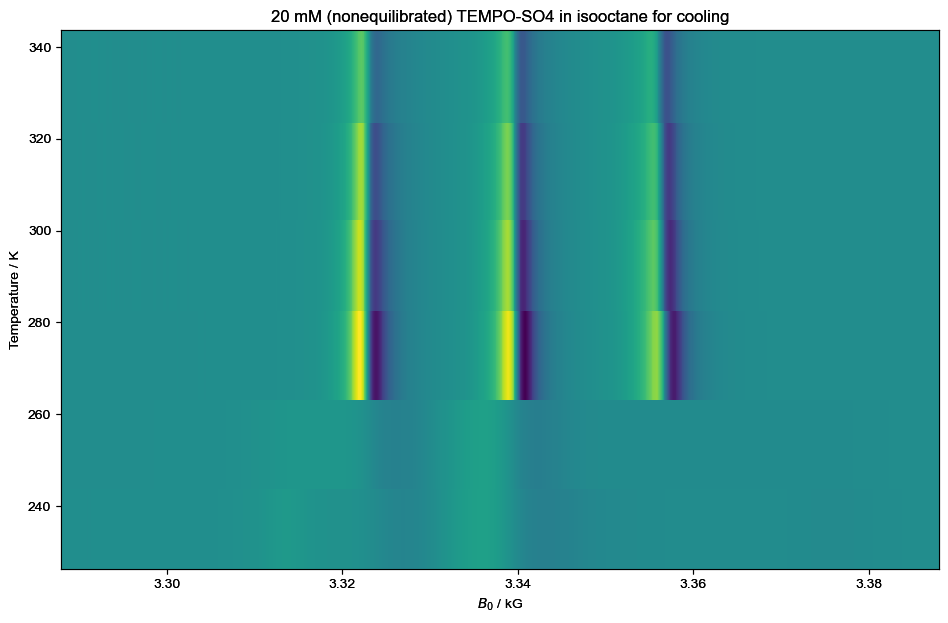

In [3]:
d_cooling = find_file("241219_TS_C8_W20_20mM_NonEqui_run1.DSC", exp_type="francklab_esr/romana") #cooling
d_cooling= d_cooling.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_cooling.reorder('Temperature').sort('Temperature')
d_cooling.pcolor()
title("20 mM (nonequilibrated) TEMPO-SO4 in isooctane for cooling")
show()

I'm having error to plot. Then using chat GPT I found duplicate on data.

In [4]:
temp_values = d_cooling.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("1",temp_values)
print("2. Duplicates in Temperature axis:", duplicates)

1 [234.897 252.32  273.713 291.086 313.326 333.535]
2. Duplicates in Temperature axis: []


## Check field ranges for the three lines

<!-- let's use 300 and 220 K as examples for where the peaks are located in the "high-temp" vs. "low-temp" limits
 -->
<!-- RS: I will set above 260 K and below 260 K -->

## Cooling 

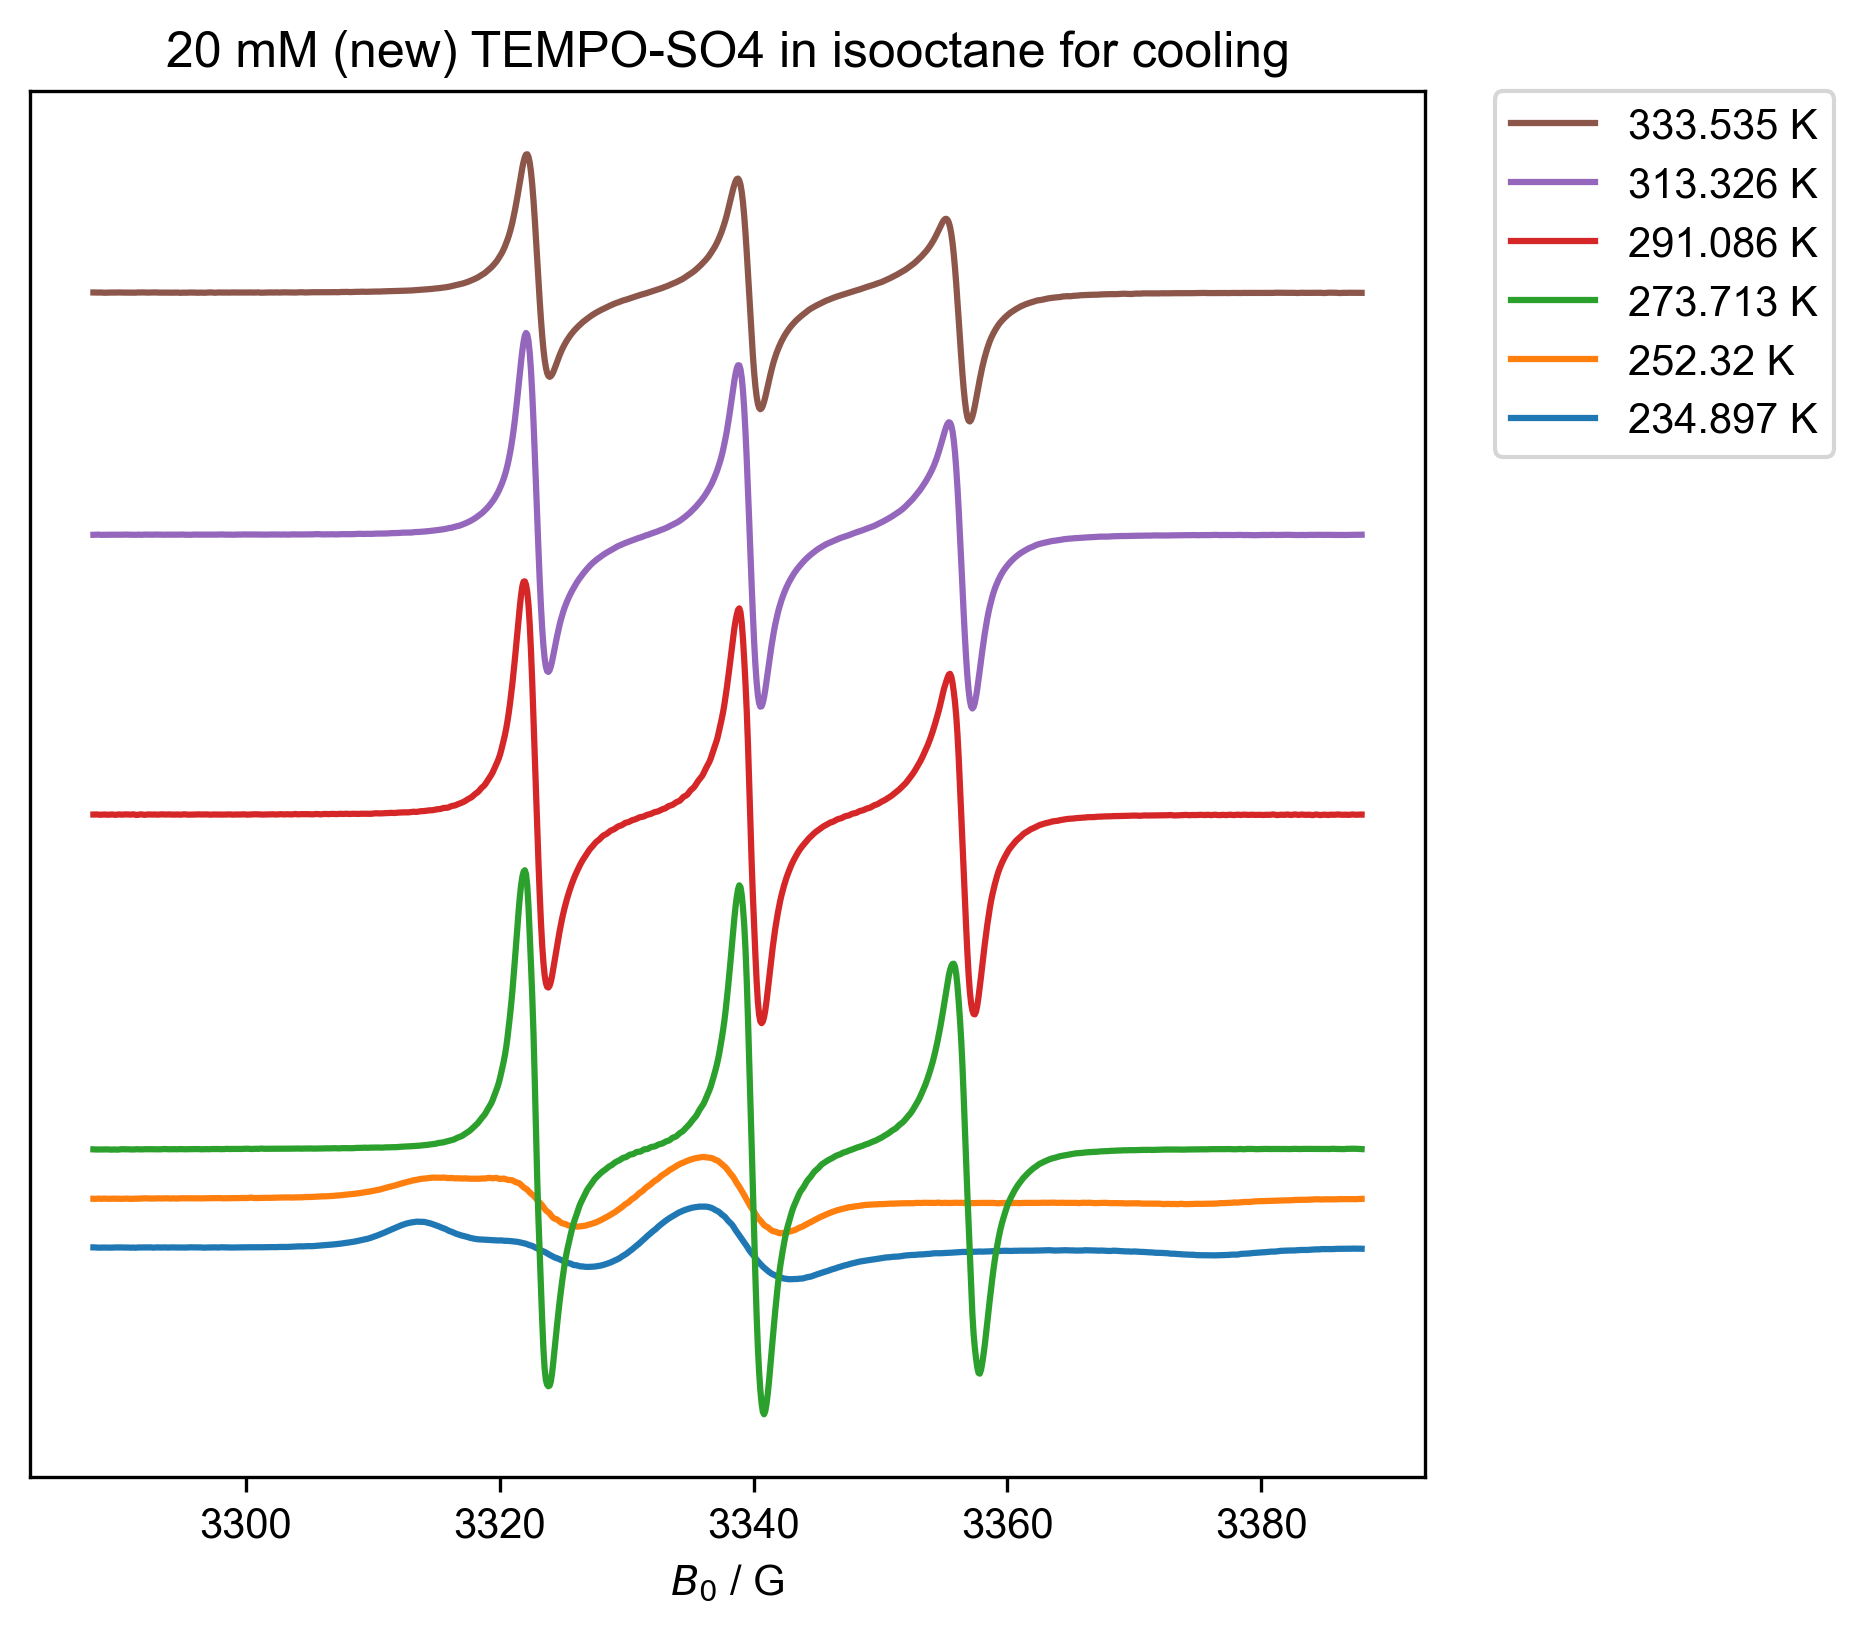

In [7]:
#cooling same plot in offset
offset= 0
d_cooling.sort("Temperature")  # Sort the data along the Temperature axis

for this_label, temp_range in [
    ("20 mM (new) TEMPO-SO4 in isooctane for cooling", (200, 350))
 ]:
    this_d1 = d_cooling["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 2.2
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.2
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()
show()

RS: For above transition, the fields are

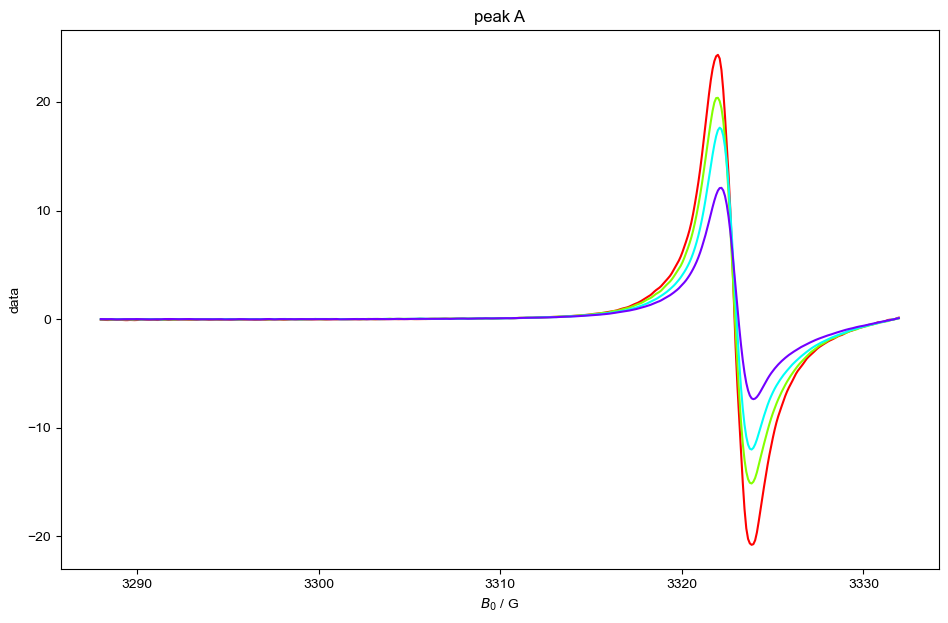

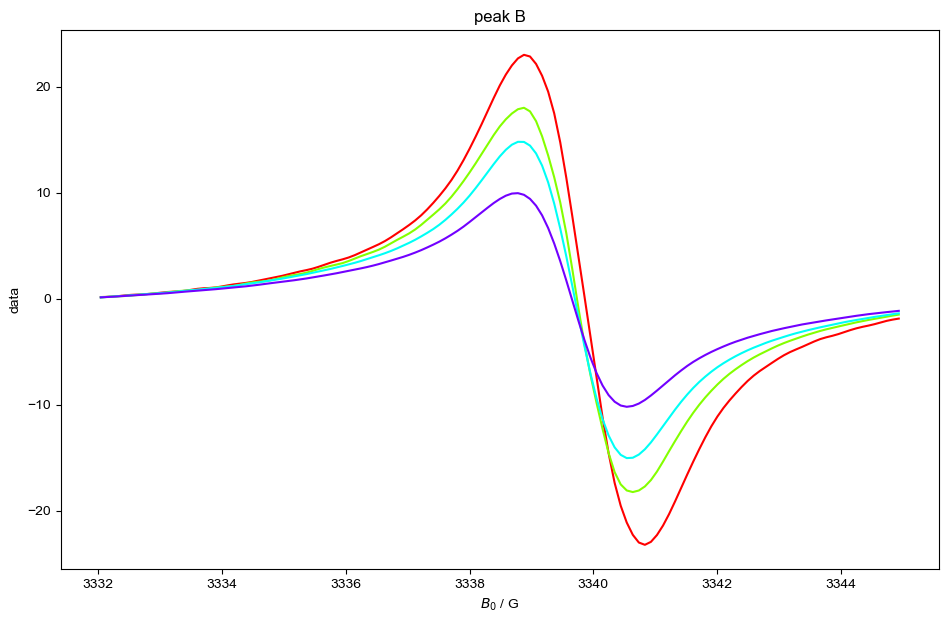

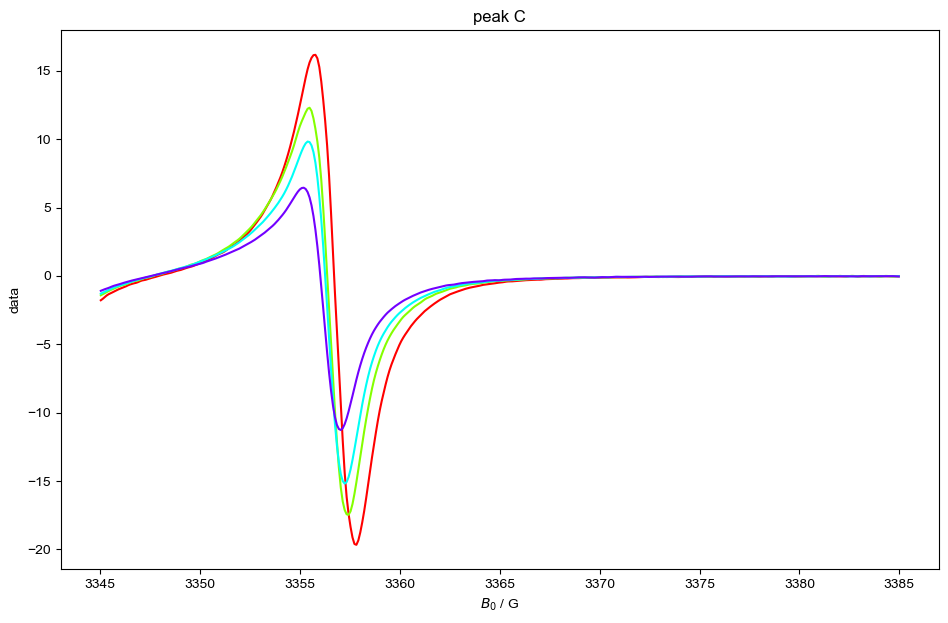

In [10]:
figure()
plot(d_cooling['Temperature':(260,None)]['$B_0$':(3285,3332)]) # peak A above transition
title("peak A")
figure()
plot(d_cooling['Temperature':(260,None)]['$B_0$':(3332,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_cooling['Temperature':(260,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")
show()

RS: for below transition the fields are

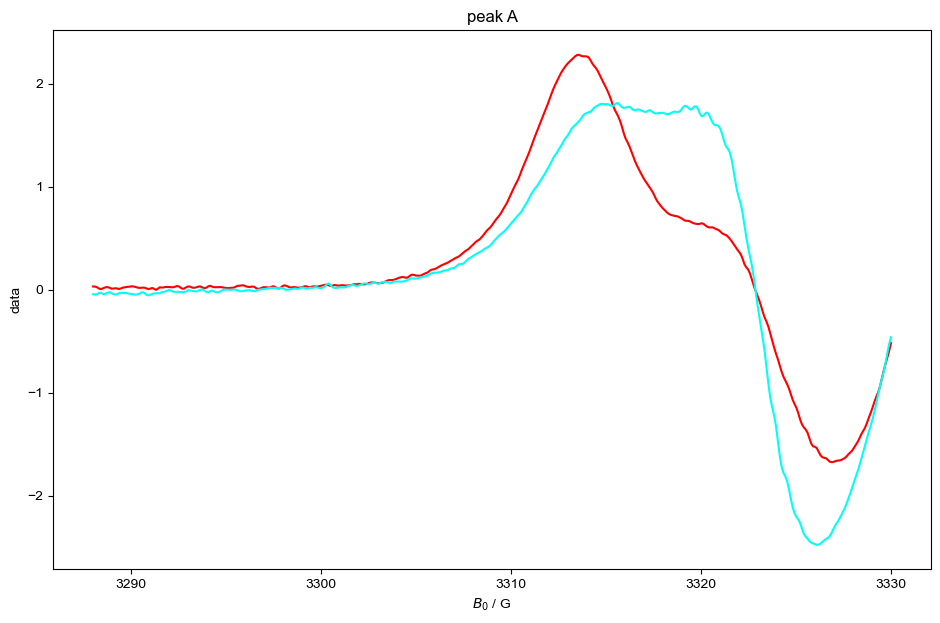

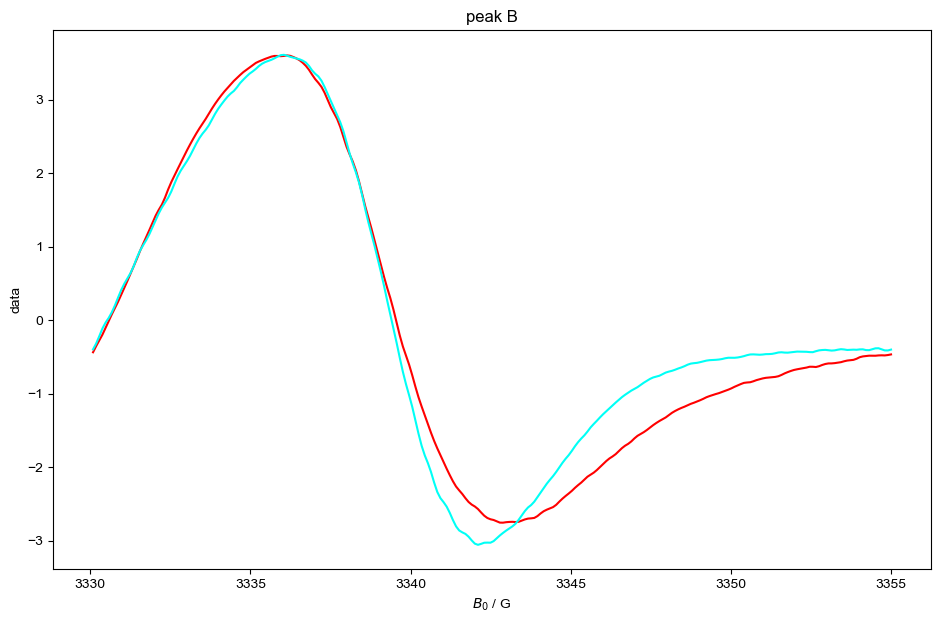

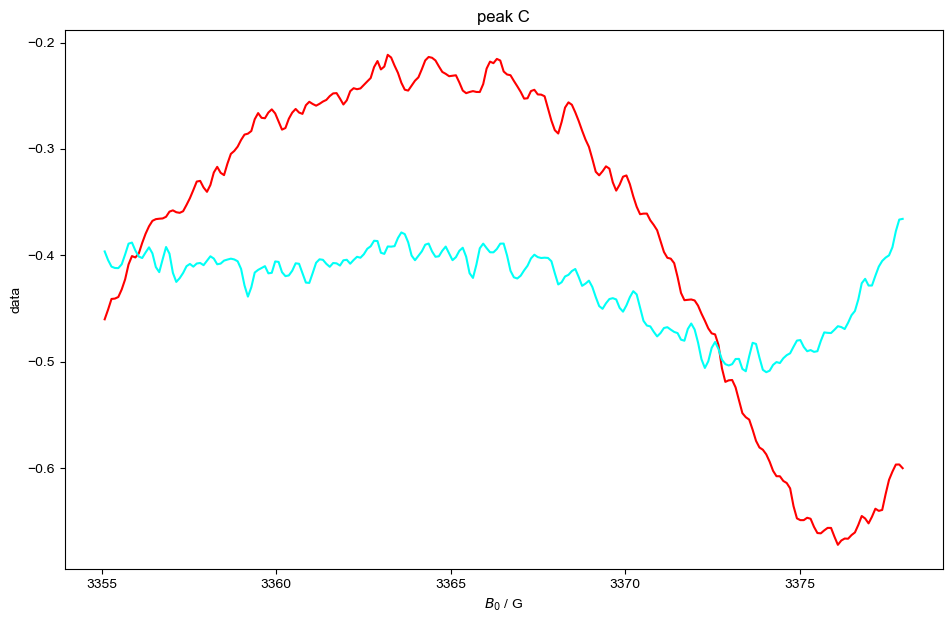

In [13]:
# RS: for below transitions fields 
figure()
plot(d_cooling['Temperature':(None,260)]['$B_0$':(3285,3330)]) # peak A below transition
title("peak A")
figure()
plot(d_cooling['Temperature':(None,260)]['$B_0$':(3330,3355)]) # peak B below transition
title("peak B")
figure()
plot(d_cooling['Temperature':(None,260)]['$B_0$':(3355,3378)]) # peak C below transition
title("peak C")
show()

# Pick the Peaks and Calculate the Correlation times

The first cell here only operates over a limited temperature range.

#### RS: All transition 

correlation time is 1.3618224863438684e-08 for temperature 202.892
correlation time is 1.3737513301048323e-08 for temperature 213.495
correlation time is 1.4197339490114704e-08 for temperature 223.461
correlation time is 1.7801319853761622e-08 for temperature 233.354
correlation time is 6.471335215530782e-10 for temperature 242.073
correlation time is 3.291365796654994e-10 for temperature 252.266
correlation time is 2.044121426119778e-10 for temperature 262.273
correlation time is 1.749784294937709e-10 for temperature 272.505
correlation time is 1.5669091215316442e-10 for temperature 282.371
correlation time is 1.4131632893384722e-10 for temperature 292.898
correlation time is 1.1987704567934917e-10 for temperature 302.299
correlation time is 1.0760567685616206e-10 for temperature 312.261
correlation time is 9.776176114373248e-11 for temperature 322.198
correlation time is 9.315315840589632e-11 for temperature 333.033
1: slice peak A
2: slice peak B
3: slice peak C
4: pub_fig



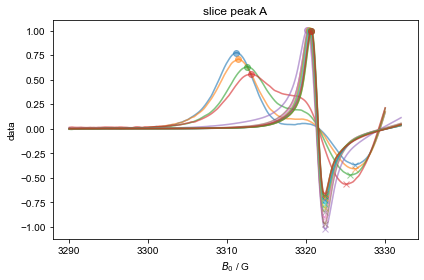

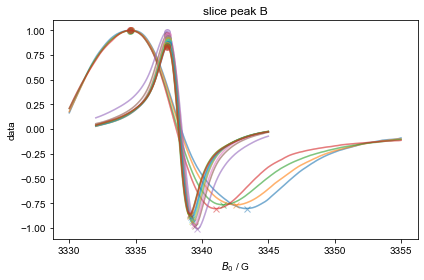

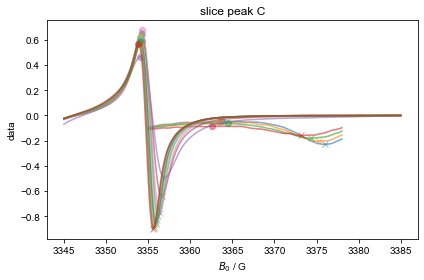

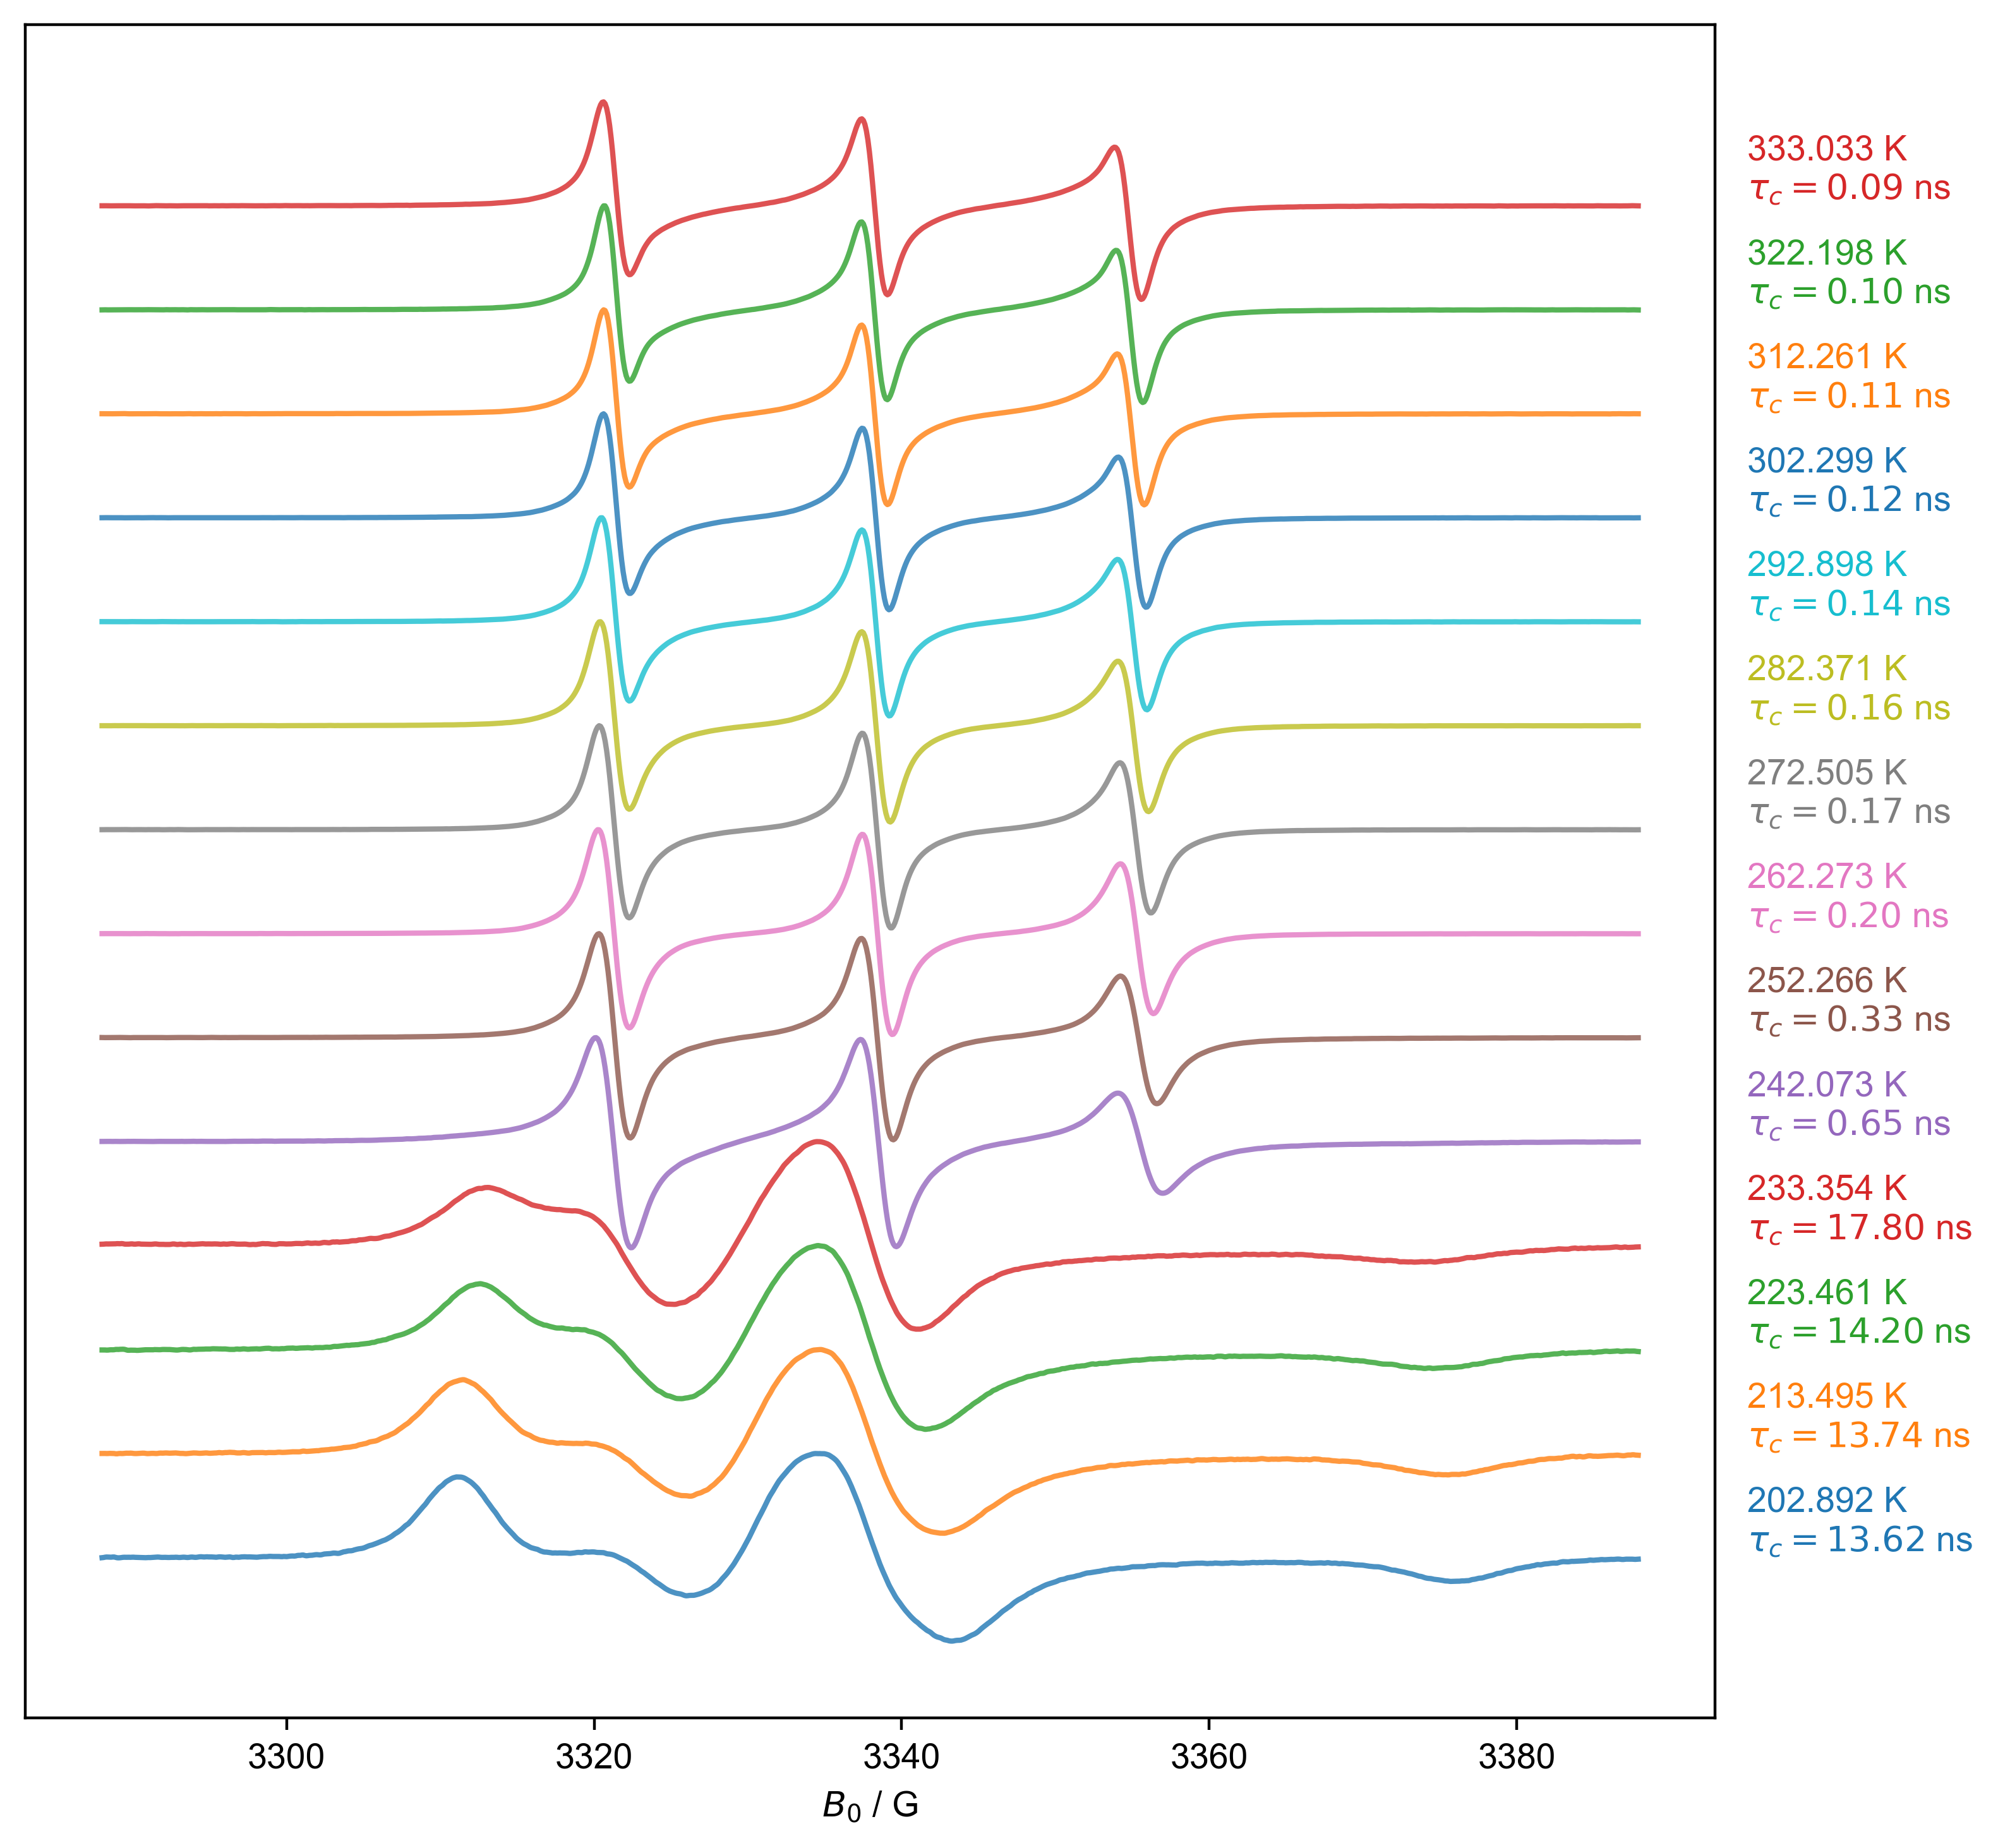

In [11]:
correlation_time_cooling = {}
all_data= d_cooling['Temperature':(None, None)] 
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 240:
            peak_A_range = (3290, 3332)
            peak_B_range = (3332, 3345)
            peak_C_range = (3345, 3385)      
        else:
            peak_A_range = (3290, 3330)
            peak_B_range = (3330, 3355)
            peak_C_range = (3355, 3378)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(8,12/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c, "for temperature", this_temp)
        correlation_time_cooling[label_str] = tau_c 
        plt.gca().text(
                3395,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.2f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1
        #xlim(3375,3550)
        j_counter += 1.1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [12]:
correlation_time_cooling

{'202.892': 1.3618224863438684e-08,
 '213.495': 1.3737513301048323e-08,
 '223.461': 1.4197339490114704e-08,
 '233.354': 1.7801319853761622e-08,
 '242.073': 6.471335215530782e-10,
 '252.266': 3.291365796654994e-10,
 '262.273': 2.044121426119778e-10,
 '272.505': 1.749784294937709e-10,
 '282.371': 1.5669091215316442e-10,
 '292.898': 1.4131632893384722e-10,
 '302.299': 1.1987704567934917e-10,
 '312.261': 1.0760567685616206e-10,
 '322.198': 9.776176114373248e-11,
 '333.033': 9.315315840589632e-11}

In [13]:
temp_cooling= np.array([float(j) for j in correlation_time_cooling.keys()])
tau_cooling = np.array(list(correlation_time_cooling.values()))

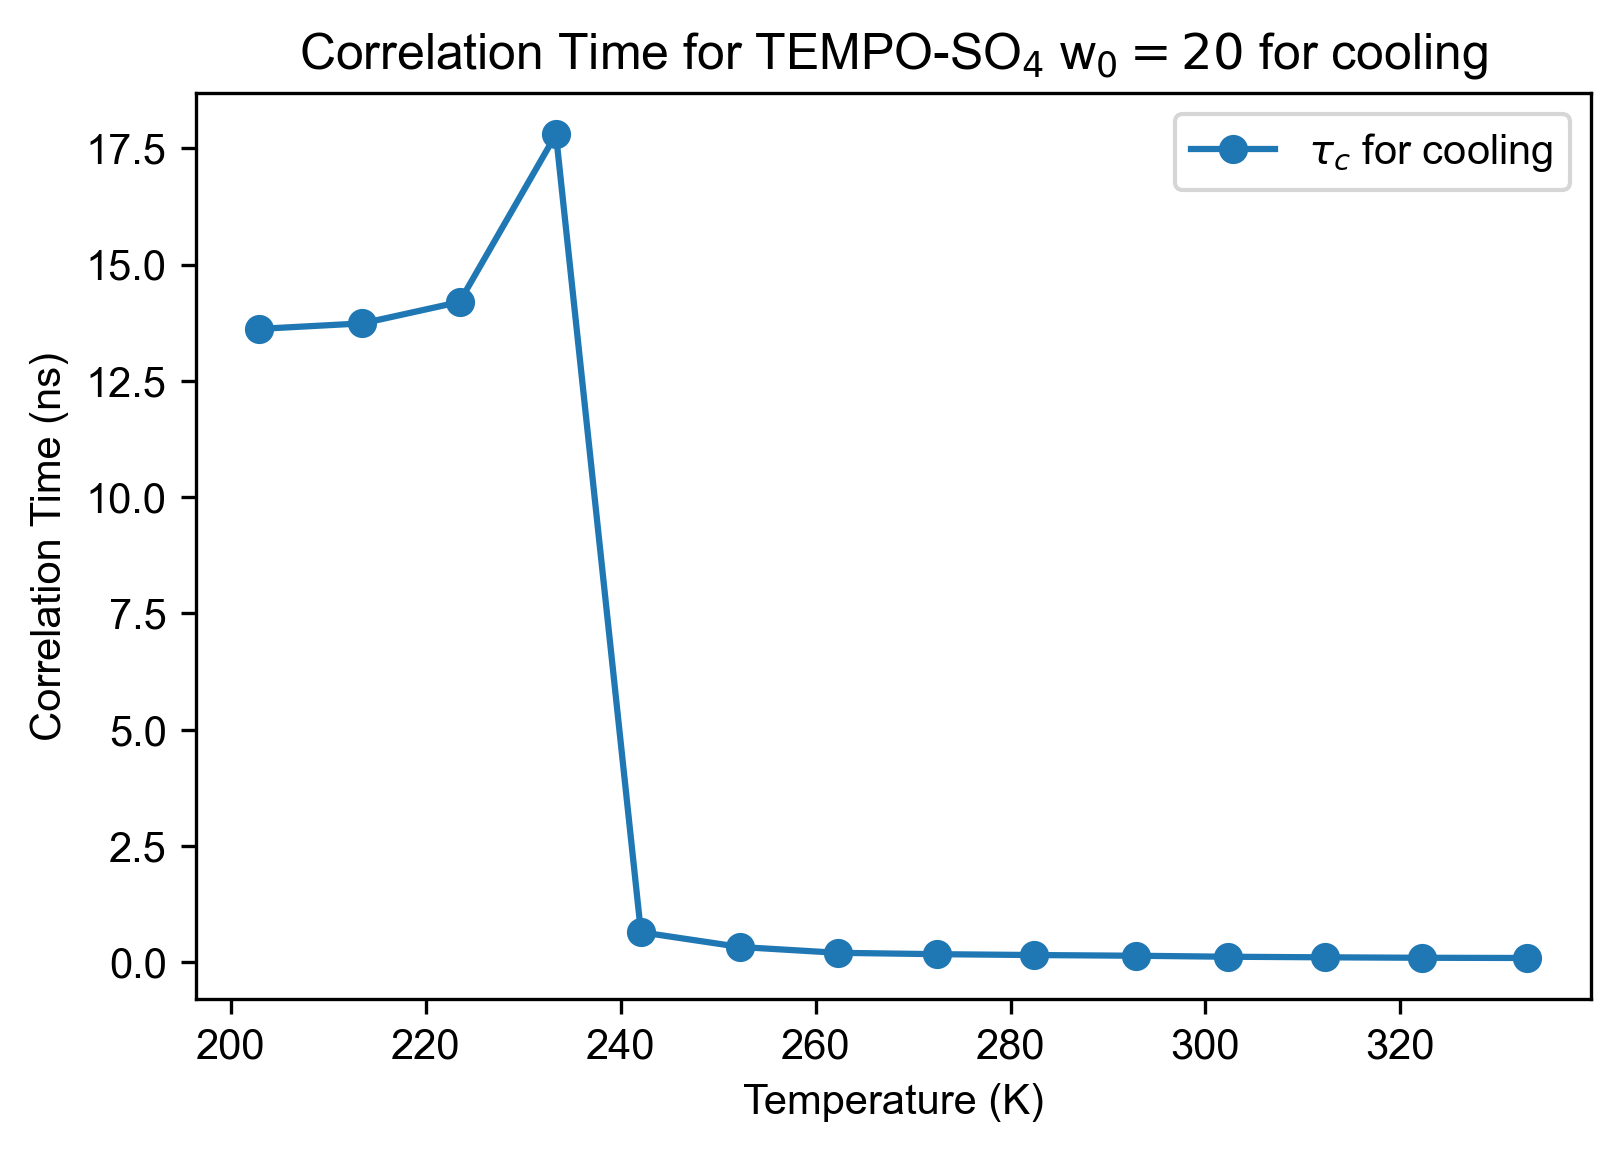

In [14]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
legend()
# xlim(253,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$ for cooling')
show()

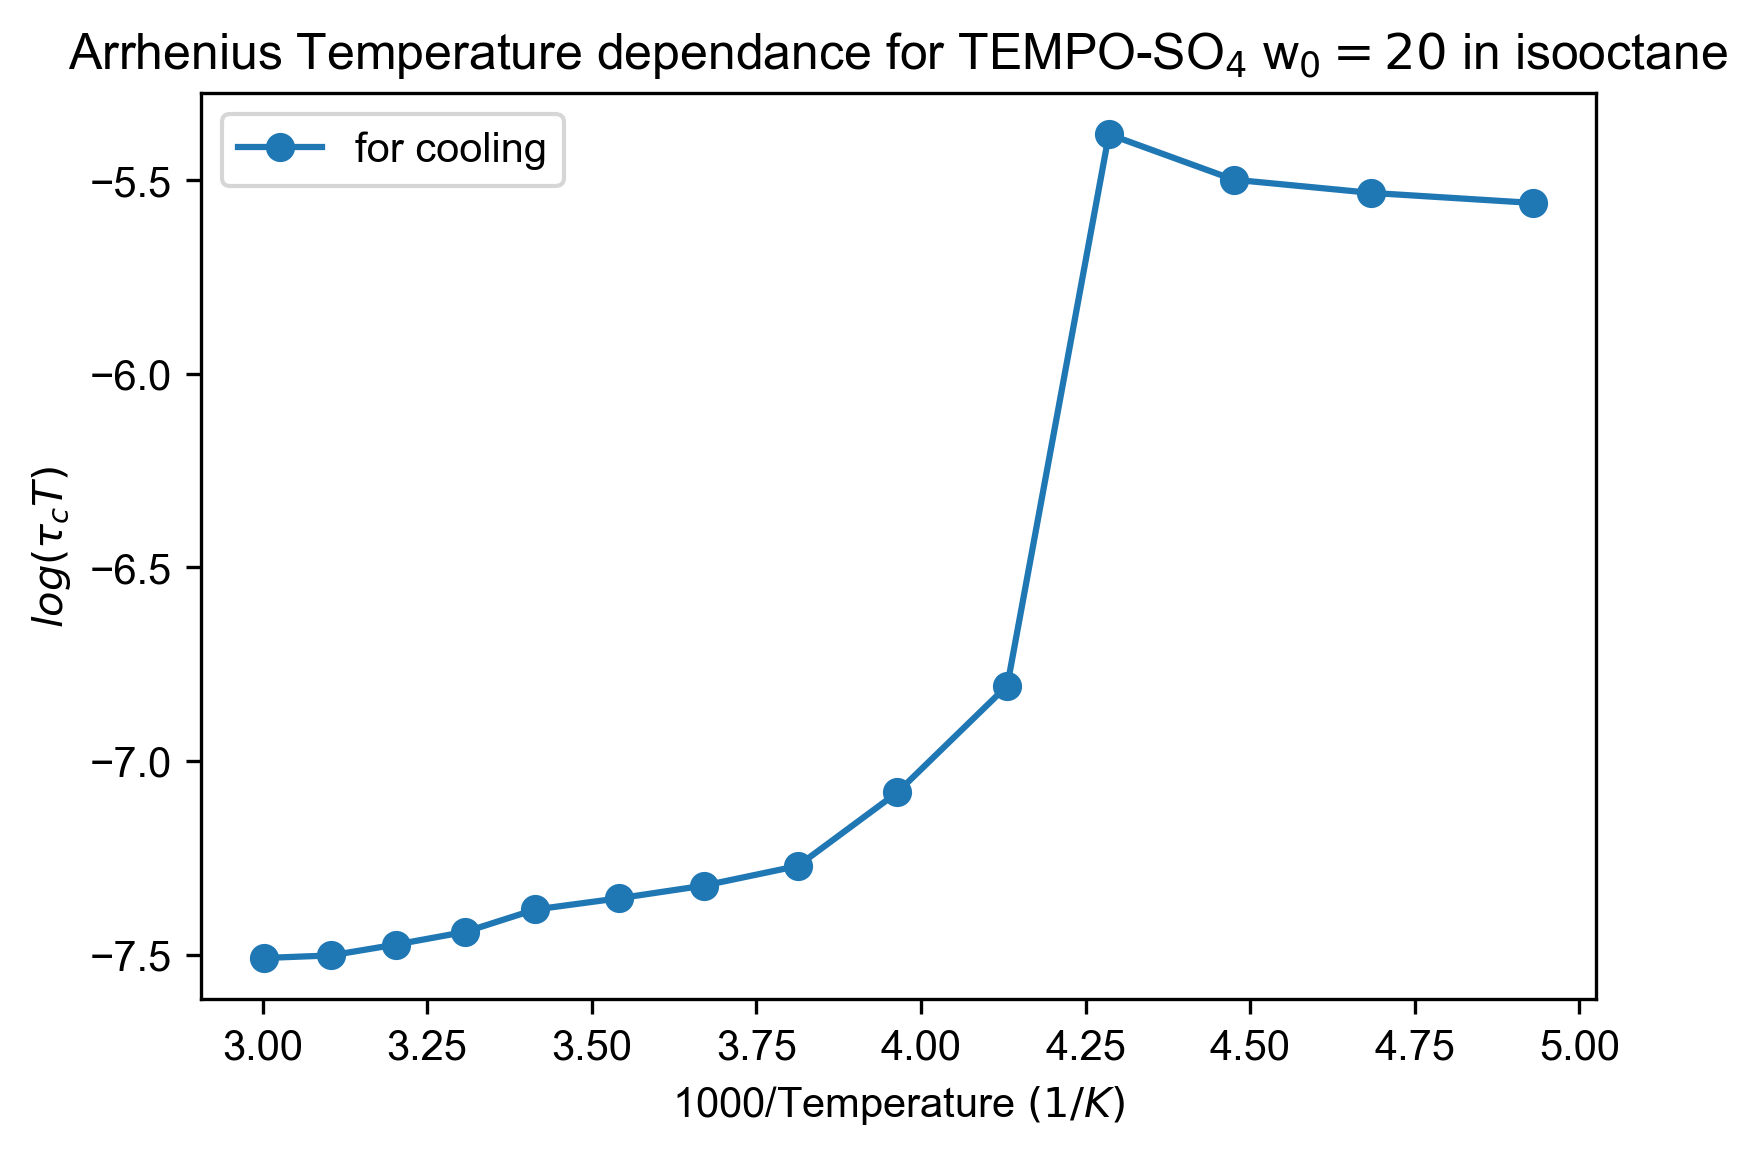

In [15]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
legend()
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane')
show()

<!-- #### RS: Below transition  -->

<!-- all_data= d_cooling['Temperature':(None,260)] # let's start just with high temp
x_counter = 0
j_counter = 0
correlation_time_below={}
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 260:
            peak_A_range = (3340,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3375,3395)
        elif this_temp >= 253:
            peak_A_range = (3320,3358)
            peak_B_range = (3358,3382)
            peak_C_range = (3387,3404)
        else:
            peak_A_range = (3320,3358)
            peak_B_range = (3358,3382)
            peak_C_range = (3382,3406)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=2e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_below[label_str] = tau_c 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('below transition for cooling TEMPO-SO$_4$ w$_0=20$ in isooctane')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False) -->

<!-- # correlation_time_below -->

<!-- # temp= [float(temp) for temp in correlation_time_below.keys()]
# tau_below= list(correlation_time_below.values())
# figure(dpi=300, figsize=(8,6))
# tau_ns_below = [t / 1e-9 for t in tau_below]
# plot(temp, tau_ns_below, linestyle='-',  marker='o', label=r"$\tau_c$")
# legend()
# xlabel('Temperature (K)')
# ylabel('Correlation Time (ns)')
# title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
# show() -->

## Reheating 

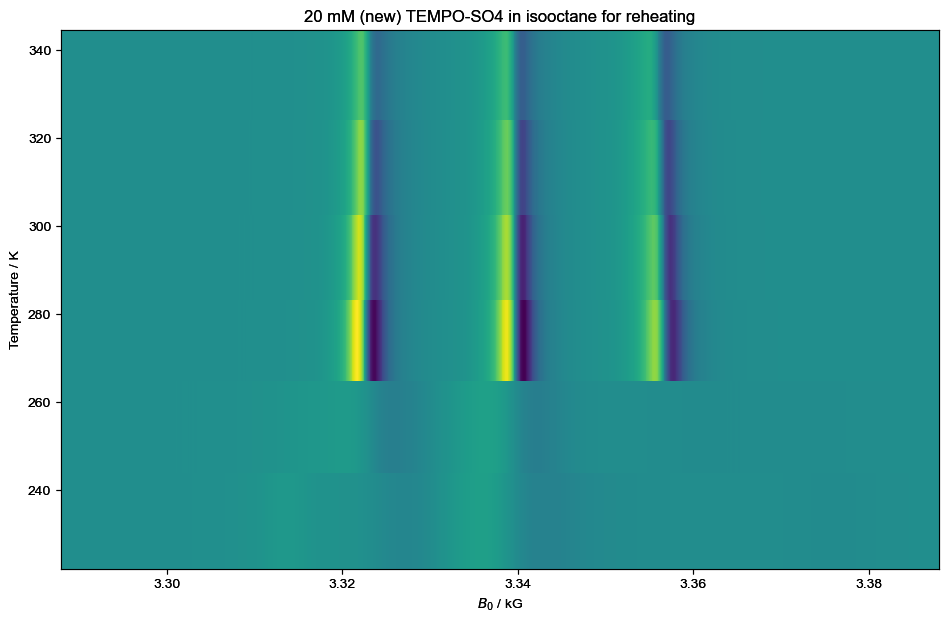

In [15]:
d_reheating = find_file("241219_TS_C8_W20_20mM_NonEqui_run2.DSC", exp_type="francklab_esr/romana") #reheating subsequently
d_reheating= d_reheating.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_reheating.reorder('Temperature').sort('Temperature')
d_reheating.pcolor()
title("20 mM (new) TEMPO-SO4 in isooctane for reheating")
show()

In [16]:
temp_values = d_reheating.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("1",temp_values)
print("2. Duplicates in Temperature axis:", duplicates)

1 [233.025 254.95  274.907 291.464 313.832 334.303]
2. Duplicates in Temperature axis: []


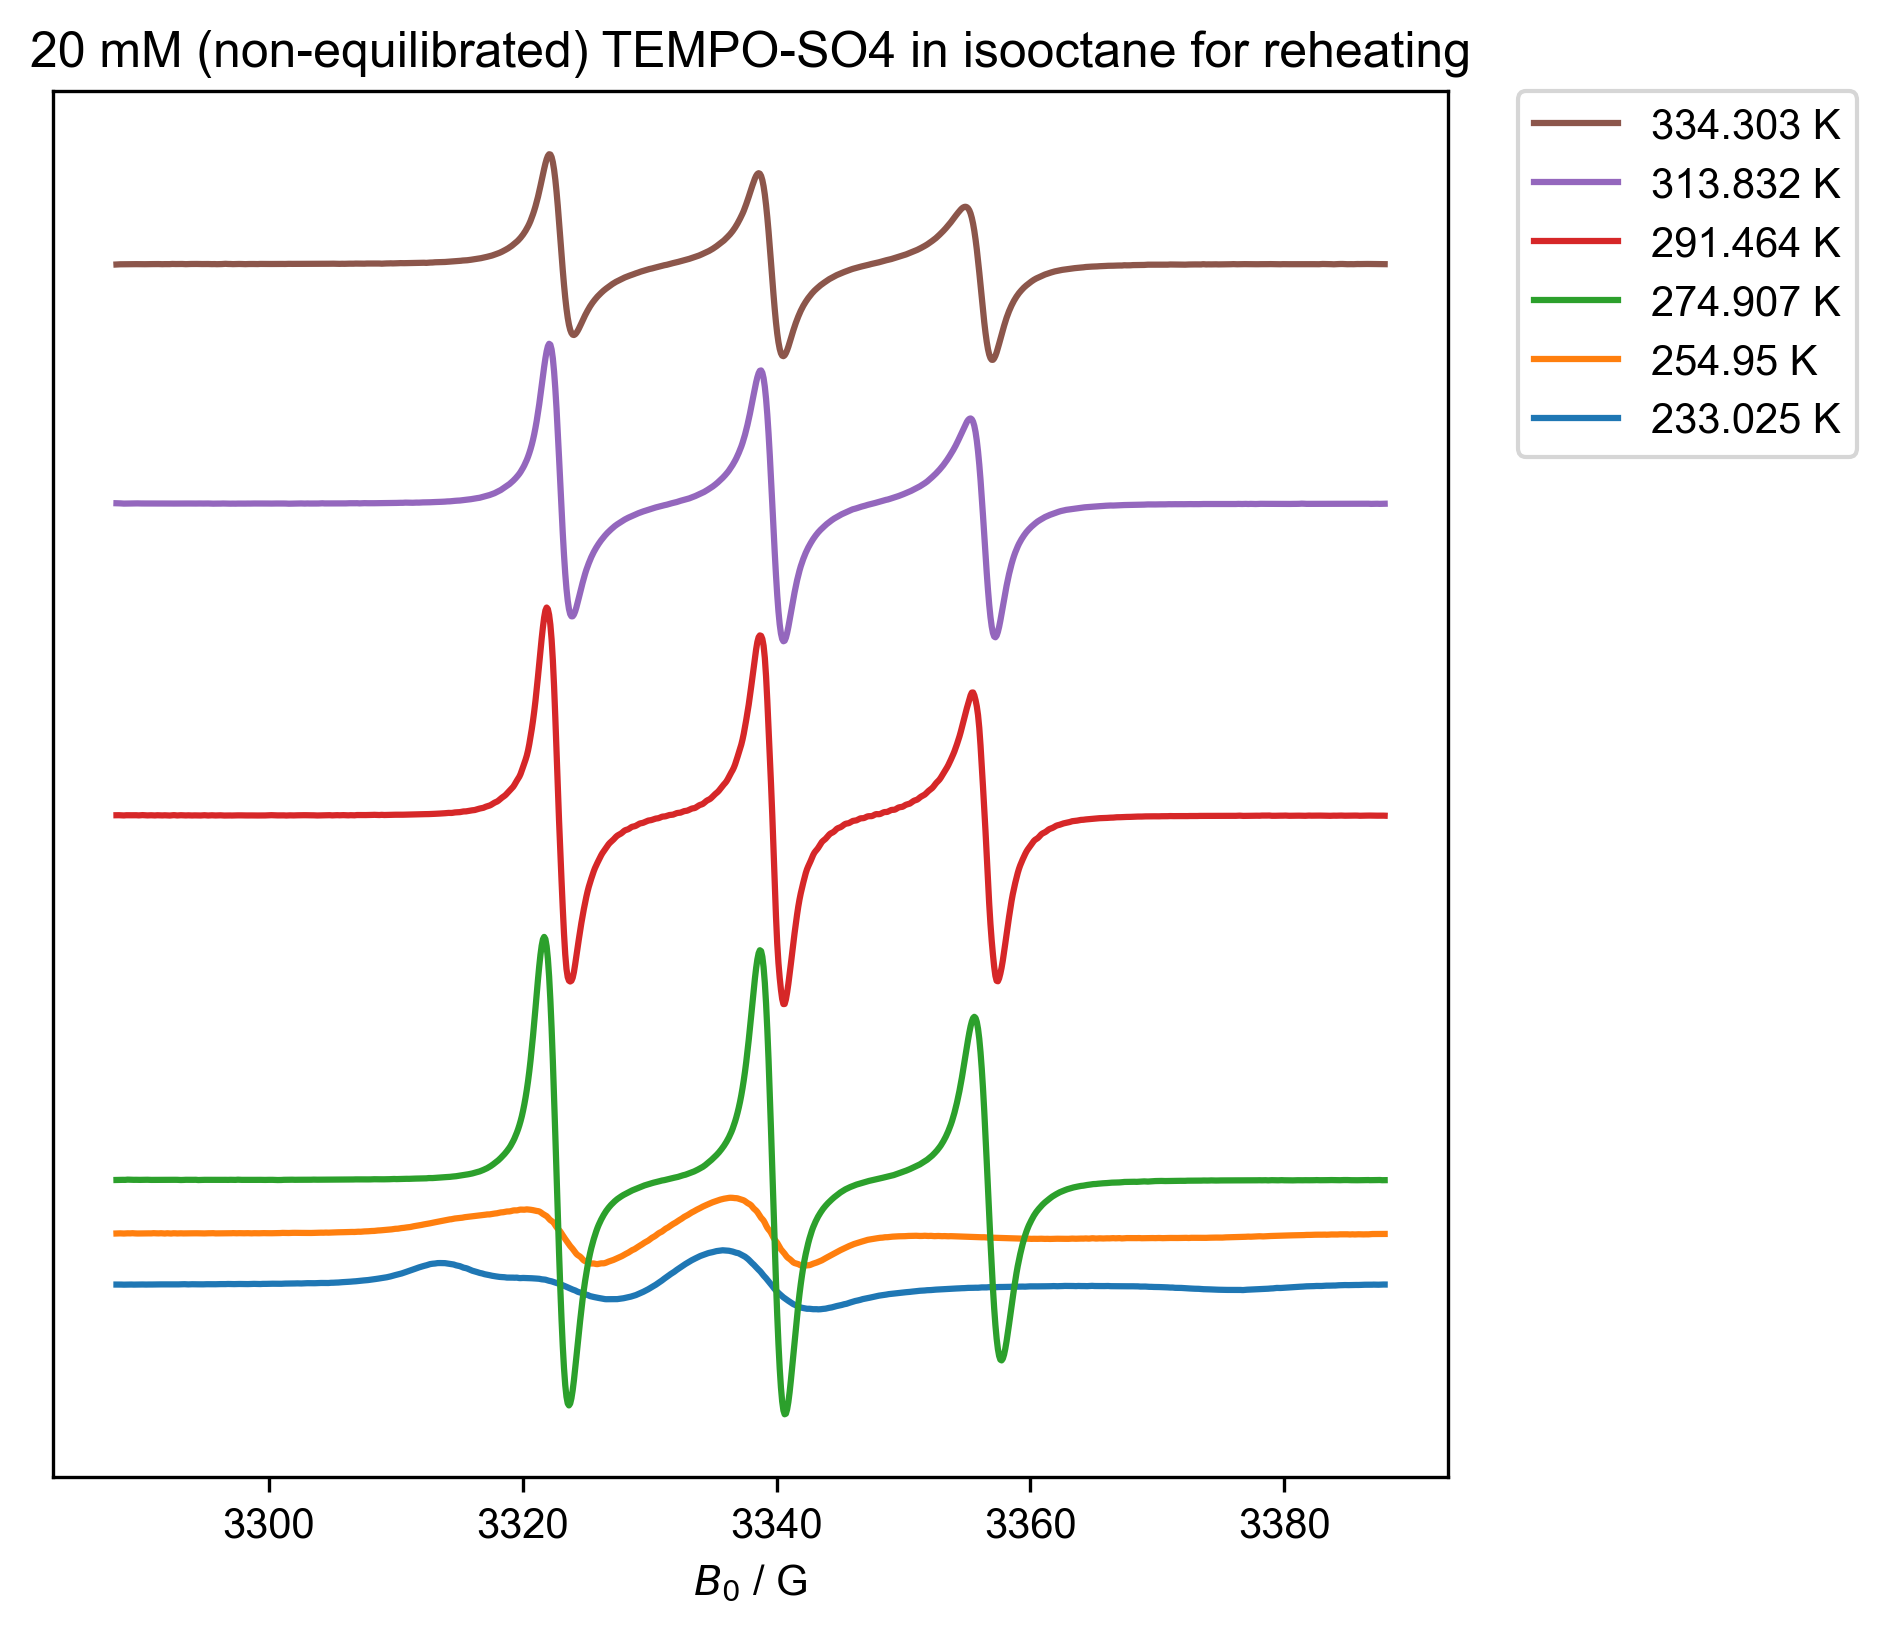

In [19]:
#cooling same plot in offset
offset= 0
d_reheating.sort("Temperature")  # Sort the data along the Temperature axis

for this_label, temp_range in [
    ("20 mM (non-equilibrated) TEMPO-SO4 in isooctane for reheating", (200, 350))
 ]:
    this_d1 = d_reheating["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 2.2
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()
show()

Text(0.5, 1.0, 'peak C')

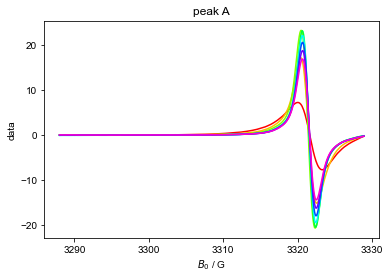

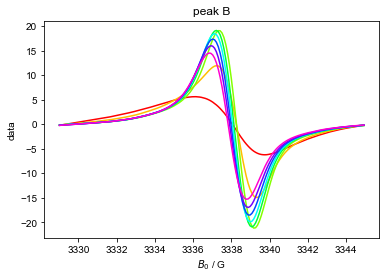

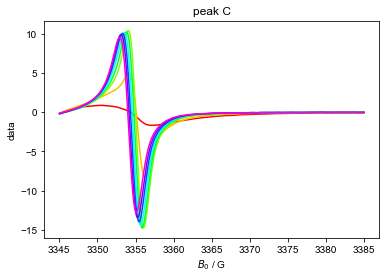

In [19]:
# RS: Above transition fields
figure()
plot(d_reheating['Temperature':(260,None)]['$B_0$':(3285,3329)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(260,None)]['$B_0$':(3329,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(260,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

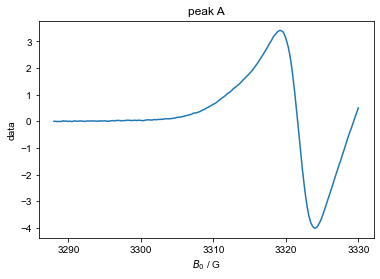

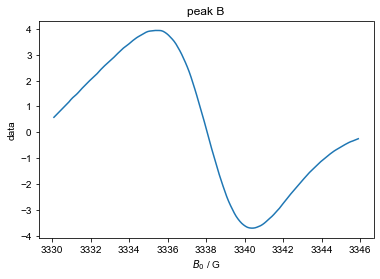

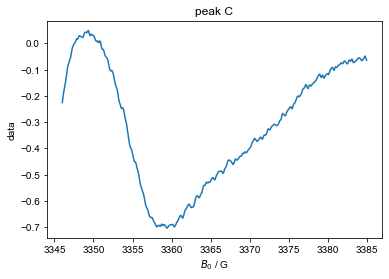

In [38]:
# RS: Intermediate 1 transition fields
figure()
plot(d_reheating['Temperature':(250,260)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(250,260)]['$B_0$':(3330,3346)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(250,260)]['$B_0$':(3346,3385)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

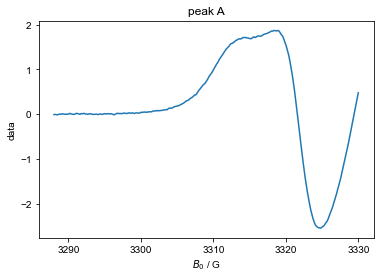

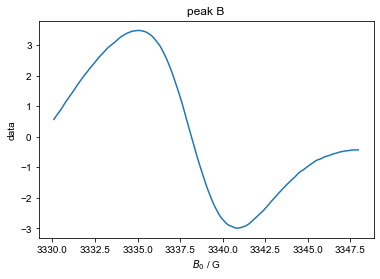

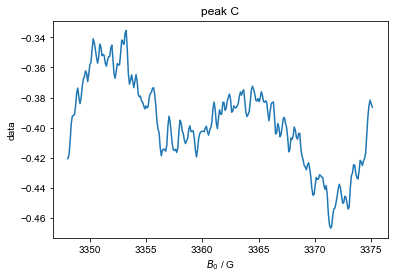

In [41]:
# RS: Intermediate 2 transition fields
figure()
plot(d_reheating['Temperature':(240,250)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(240,250)]['$B_0$':(3330,3348)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(240,250)]['$B_0$':(3348,3375.2)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

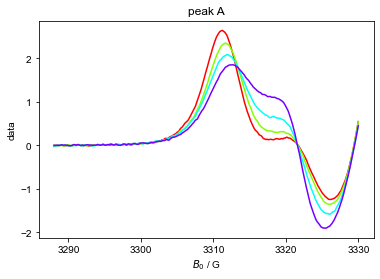

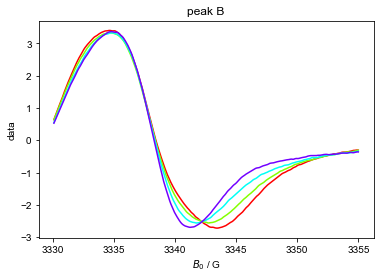

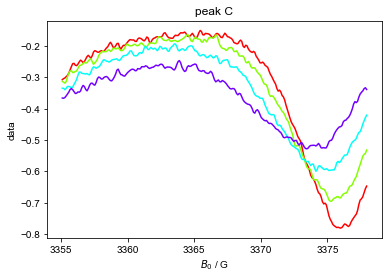

In [23]:
# RS: Below transition fields
figure()
plot(d_reheating['Temperature':(None,240)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(None,240)]['$B_0$':(3330,3355)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(None,240)]['$B_0$':(3355,3378)]) # peak C above transition
title("peak C")

#### RS: All transition

correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
correlation time is 9.315315840589632e-11
1: slice peak A
2: slice peak B
3: slice peak C
4: pub_fig



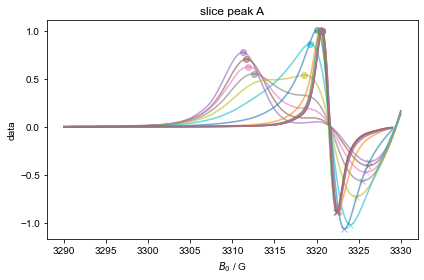

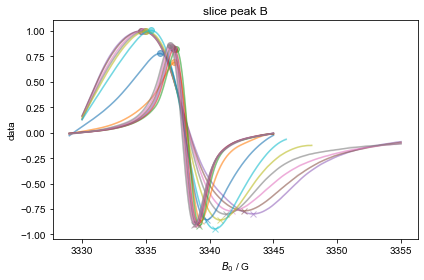

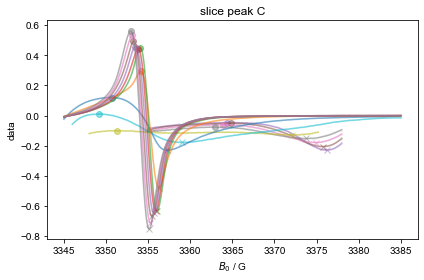

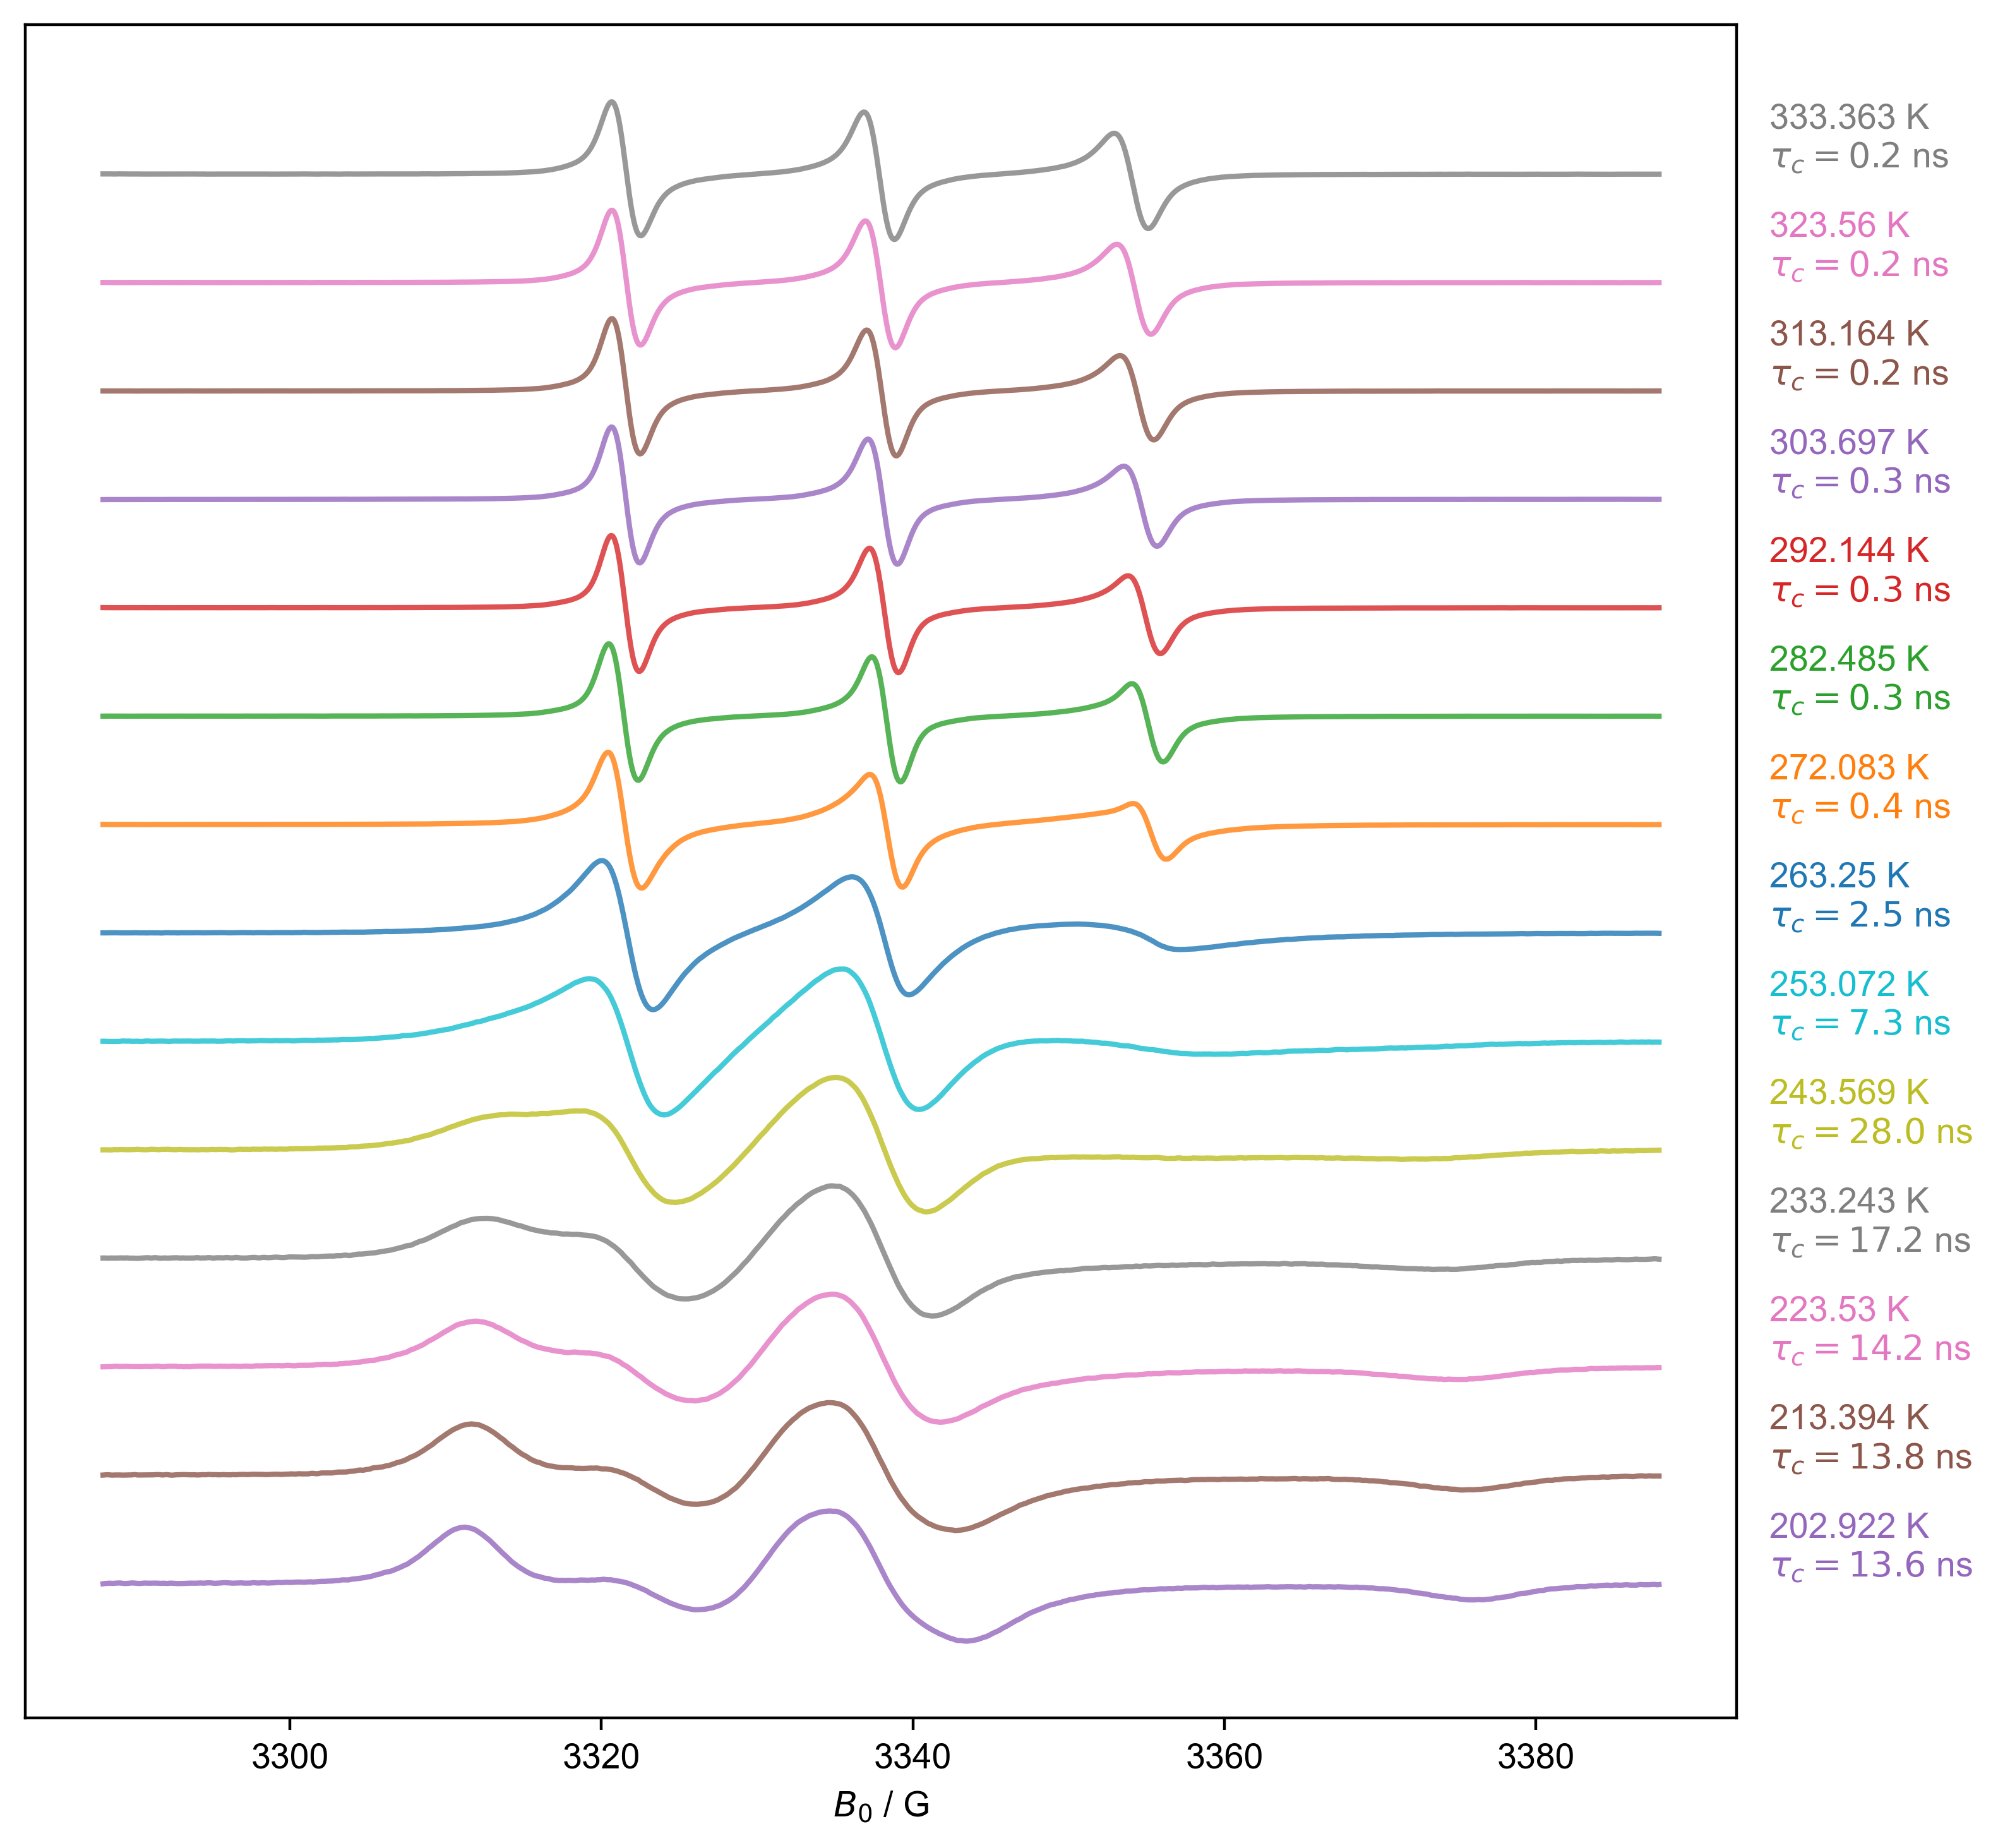

In [42]:
correlation_time_reheating = {}

all_data_reheating= d_reheating['Temperature':(None,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data_reheating['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_reheating["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data_reheating = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 260:
            peak_A_range = (3290,3329)
            peak_B_range = (3329,3345)
            peak_C_range = (3345,3385)
        elif this_temp >= 250:
            peak_A_range = (3290,3330)
            peak_B_range = (3330,3346)
            peak_C_range = (3346,3385)
        elif this_temp >= 240:
            peak_A_range = (3290,3330)
            peak_B_range = (3330,3348)
            peak_C_range = (3348,3375.2)
        else:
            peak_A_range = (3290,3330)
            peak_B_range = (3330,3355)
            peak_C_range = (3355,3378)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=3e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_reheating[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_reheating[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data_reheating[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_reheating[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data_reheating[peak_name+'maxB0'],peak_data_reheating[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data_reheating[peak_name+'minB0'],peak_data_reheating[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(8,12/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_reheating = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data_reheating)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_reheating[label_str] = tau_c_reheating 
        plt.gca().text(
                3395,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c_reheating/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [43]:
correlation_time_reheating

{'202.922': 1.3637378612899402e-08,
 '213.394': 1.3776952308593642e-08,
 '223.53': 1.419609081364736e-08,
 '233.243': 1.7225090842245245e-08,
 '243.569': 2.801342854903476e-08,
 '253.072': 7.319714067171176e-09,
 '263.25': 2.5406218685332596e-09,
 '272.083': 4.4923236641415893e-10,
 '282.485': 2.5991188114337556e-10,
 '292.144': 2.6370647389511193e-10,
 '303.697': 2.585884273978626e-10,
 '313.164': 2.351373381856246e-10,
 '323.56': 1.9821253193859266e-10,
 '333.363': 1.7188432167423152e-10}

In [44]:
temp_reheating= np.array([float(j) for j in correlation_time_reheating.keys()])
tau_reheating = np.array(list(correlation_time_reheating.values()))

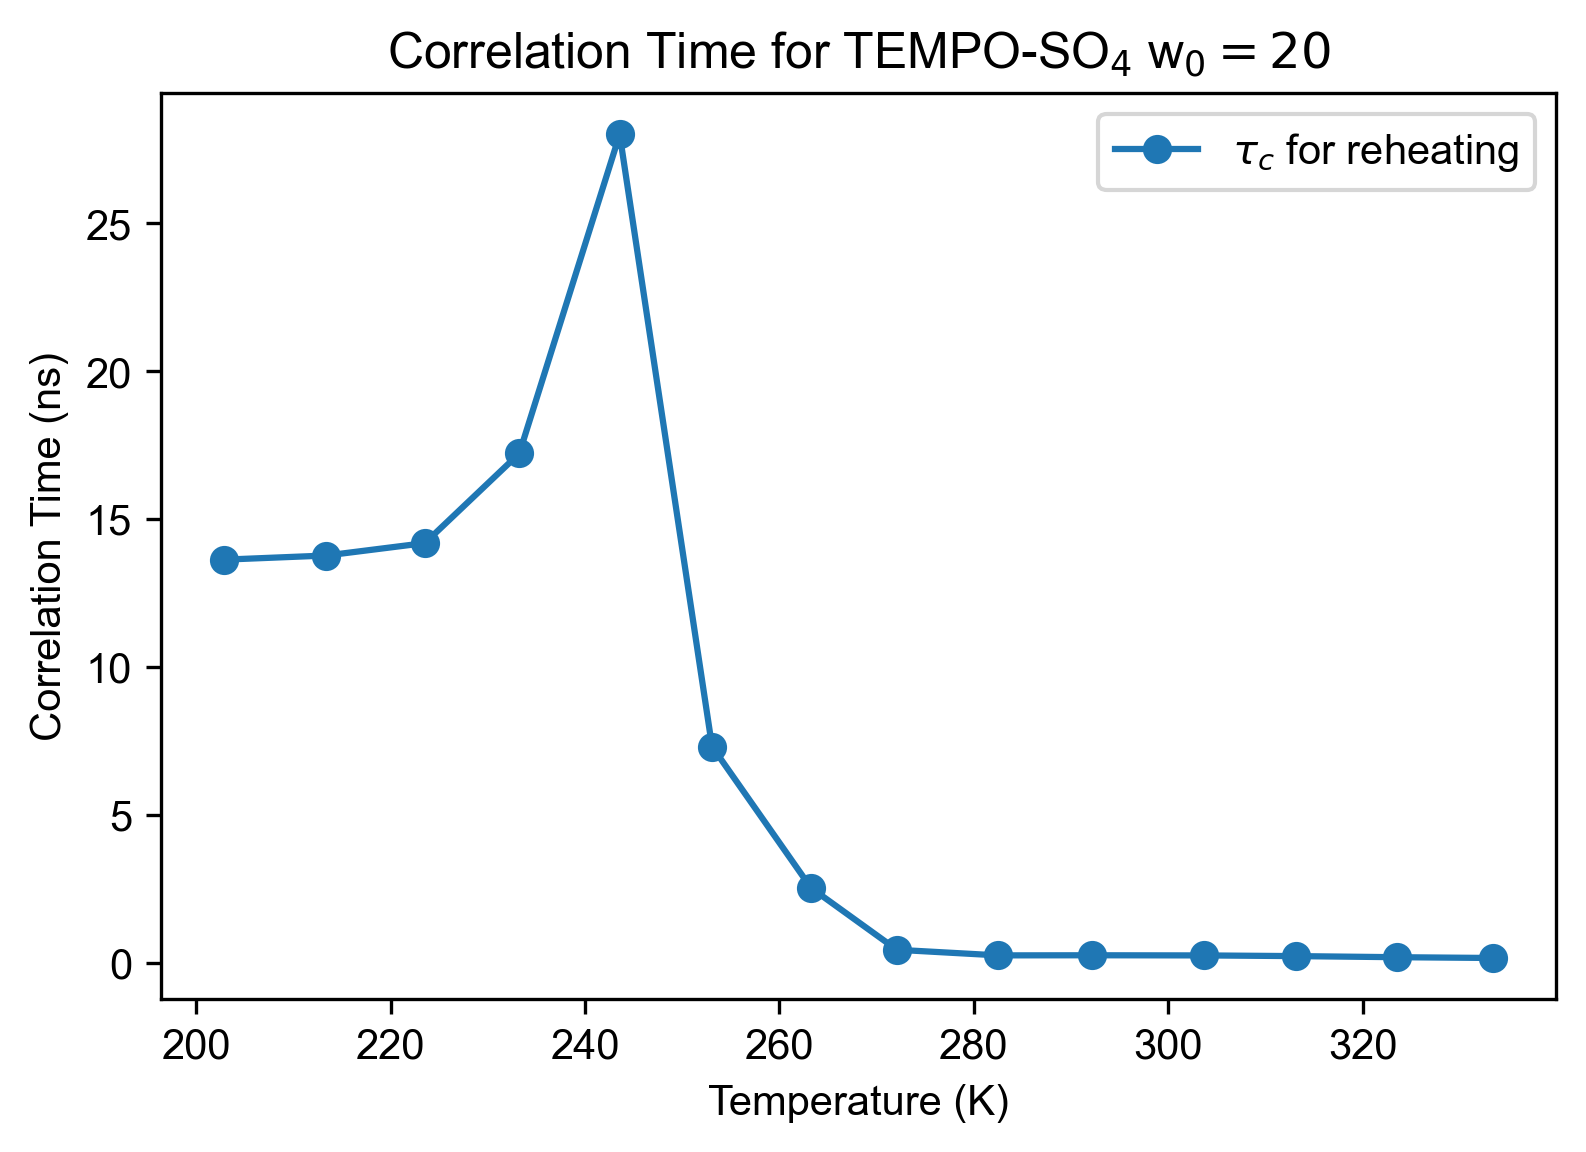

In [45]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(253,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
show()

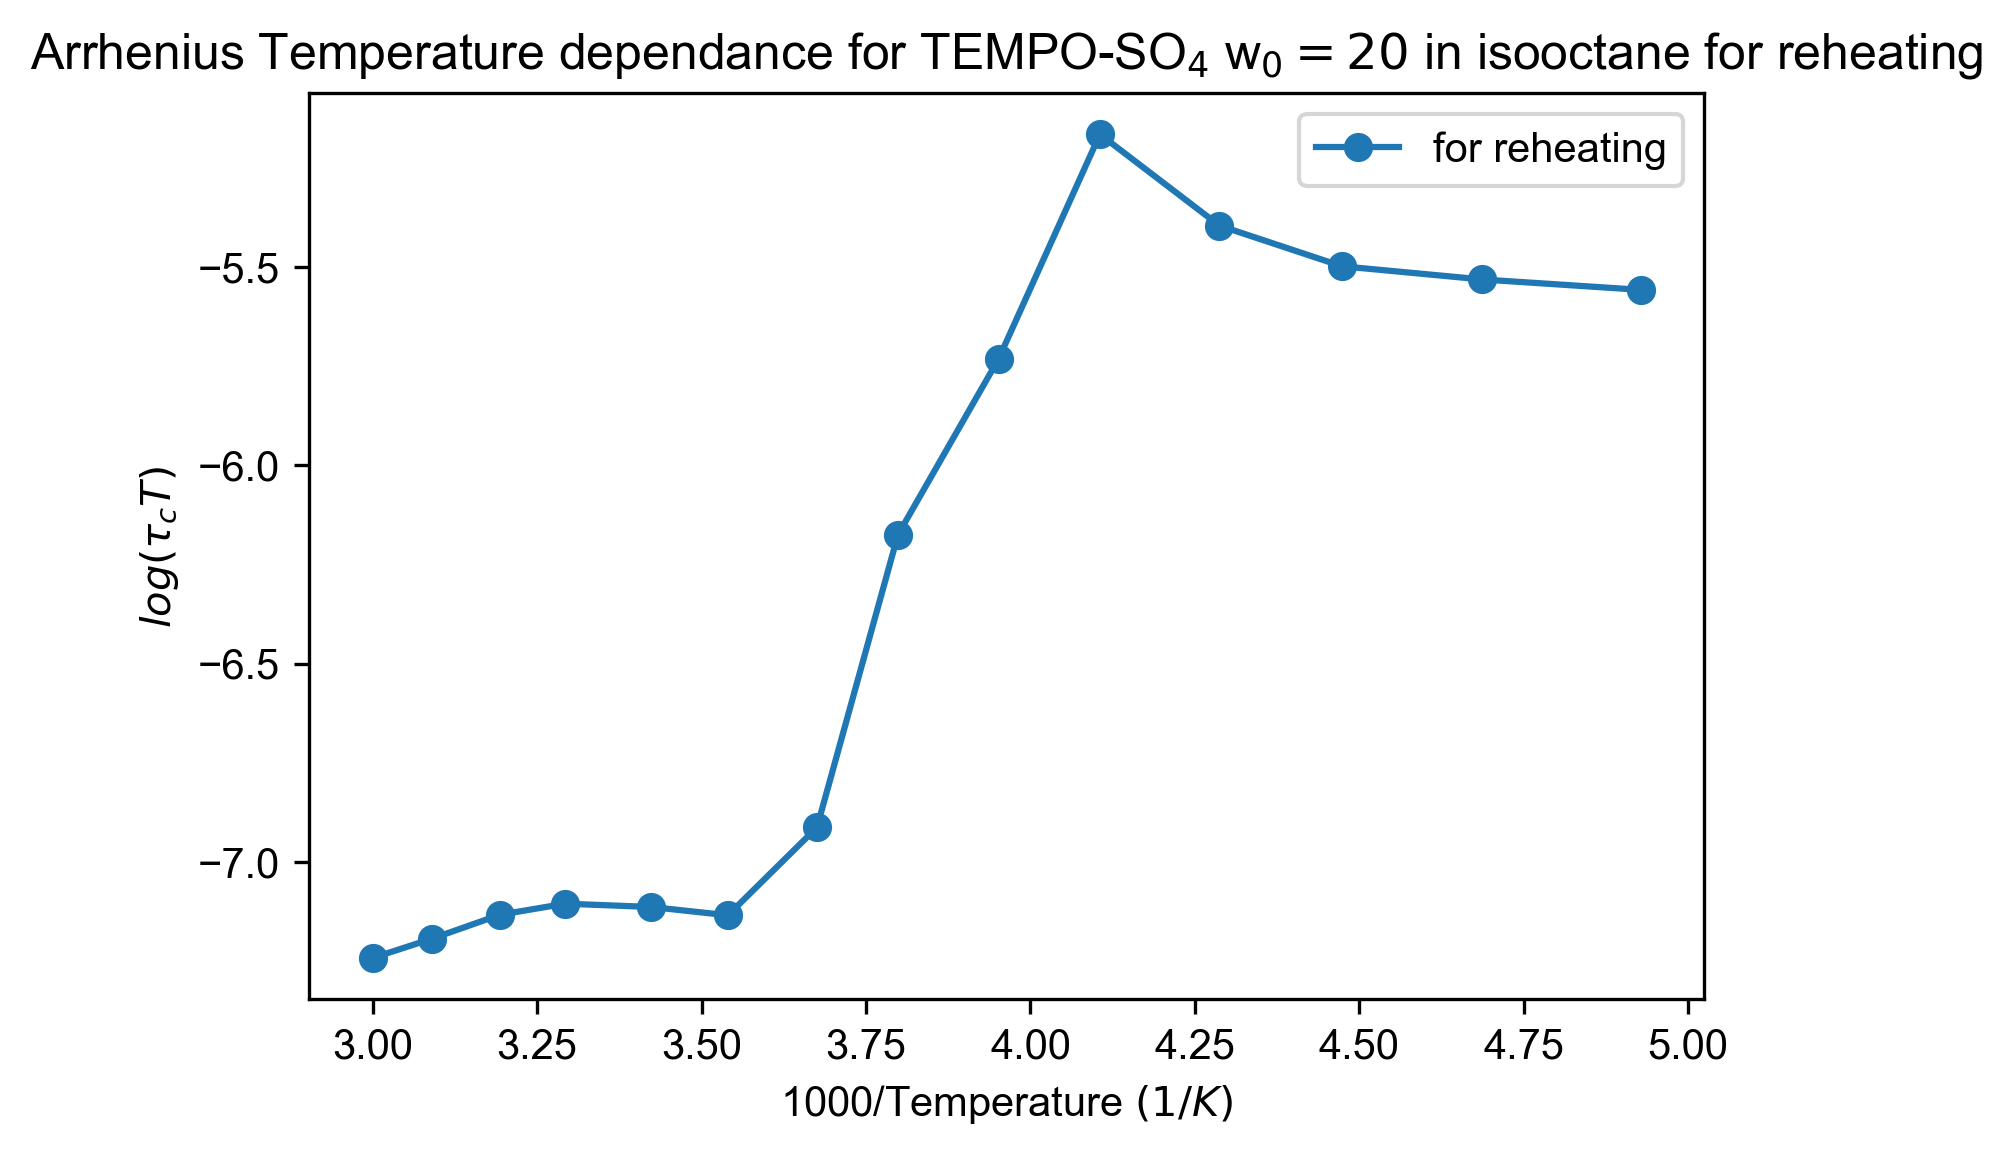

In [46]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane for reheating')
show()

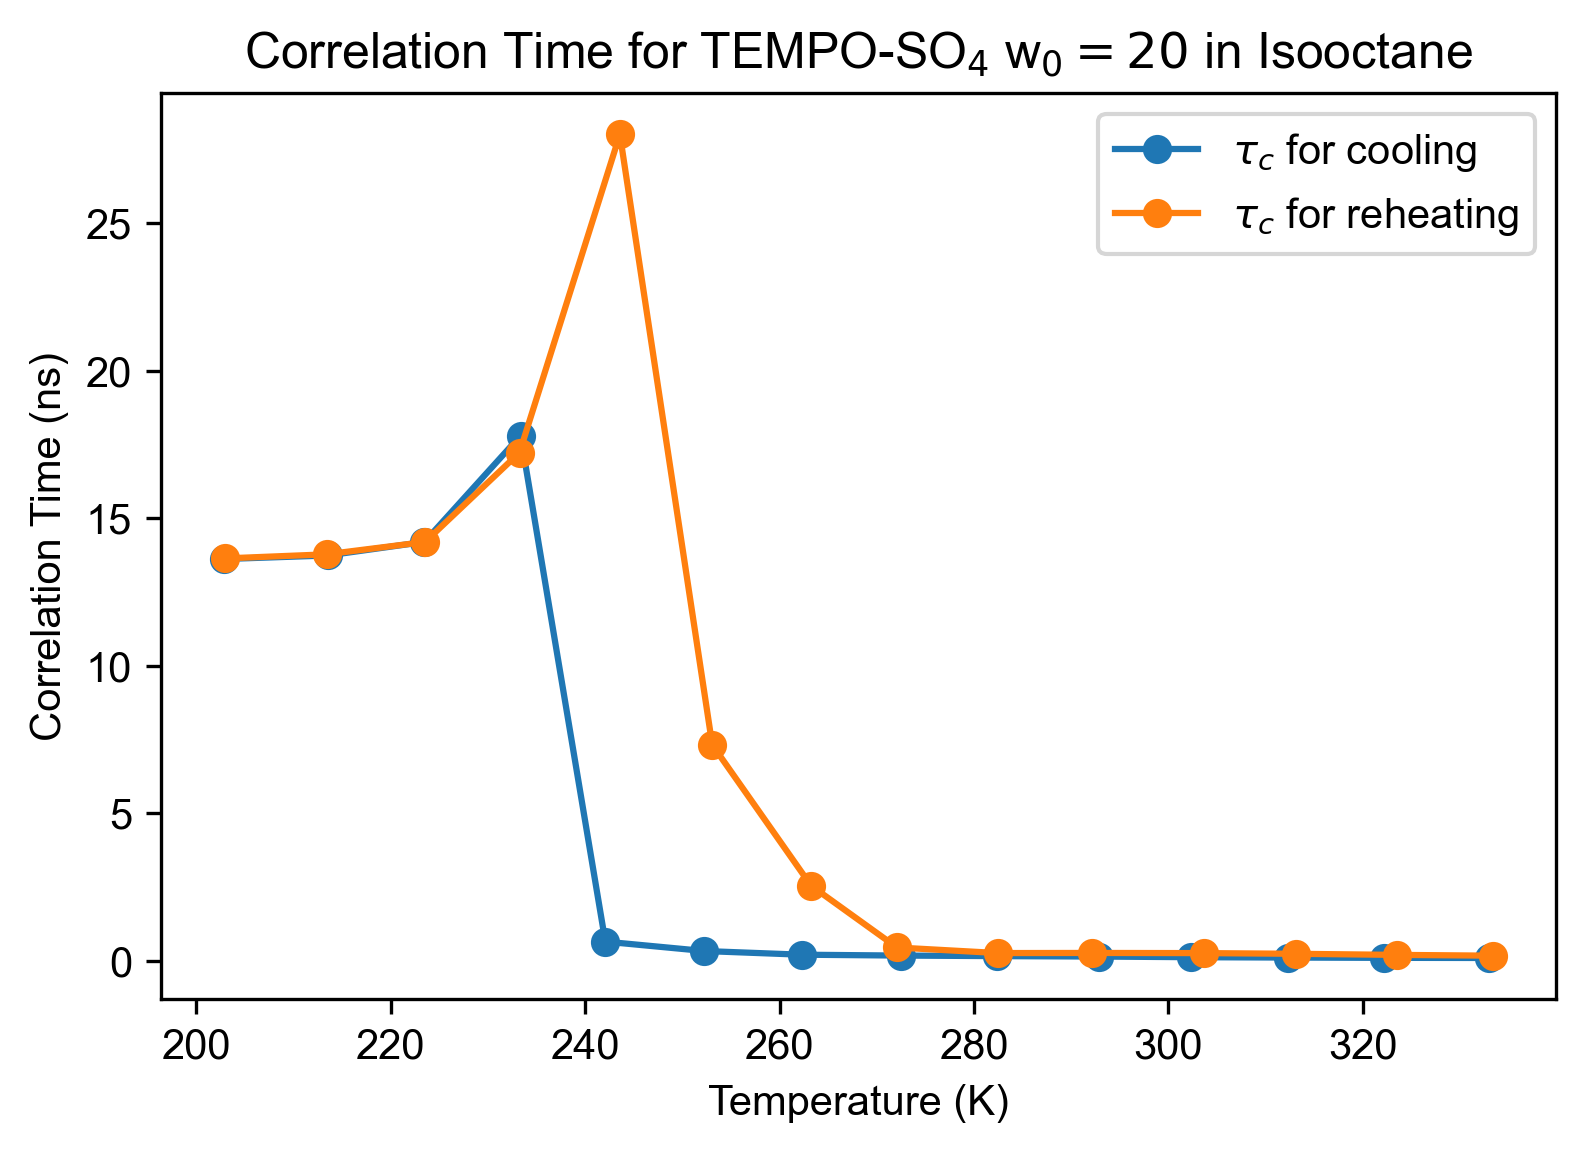

In [47]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(250,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$ in Isooctane')
show()

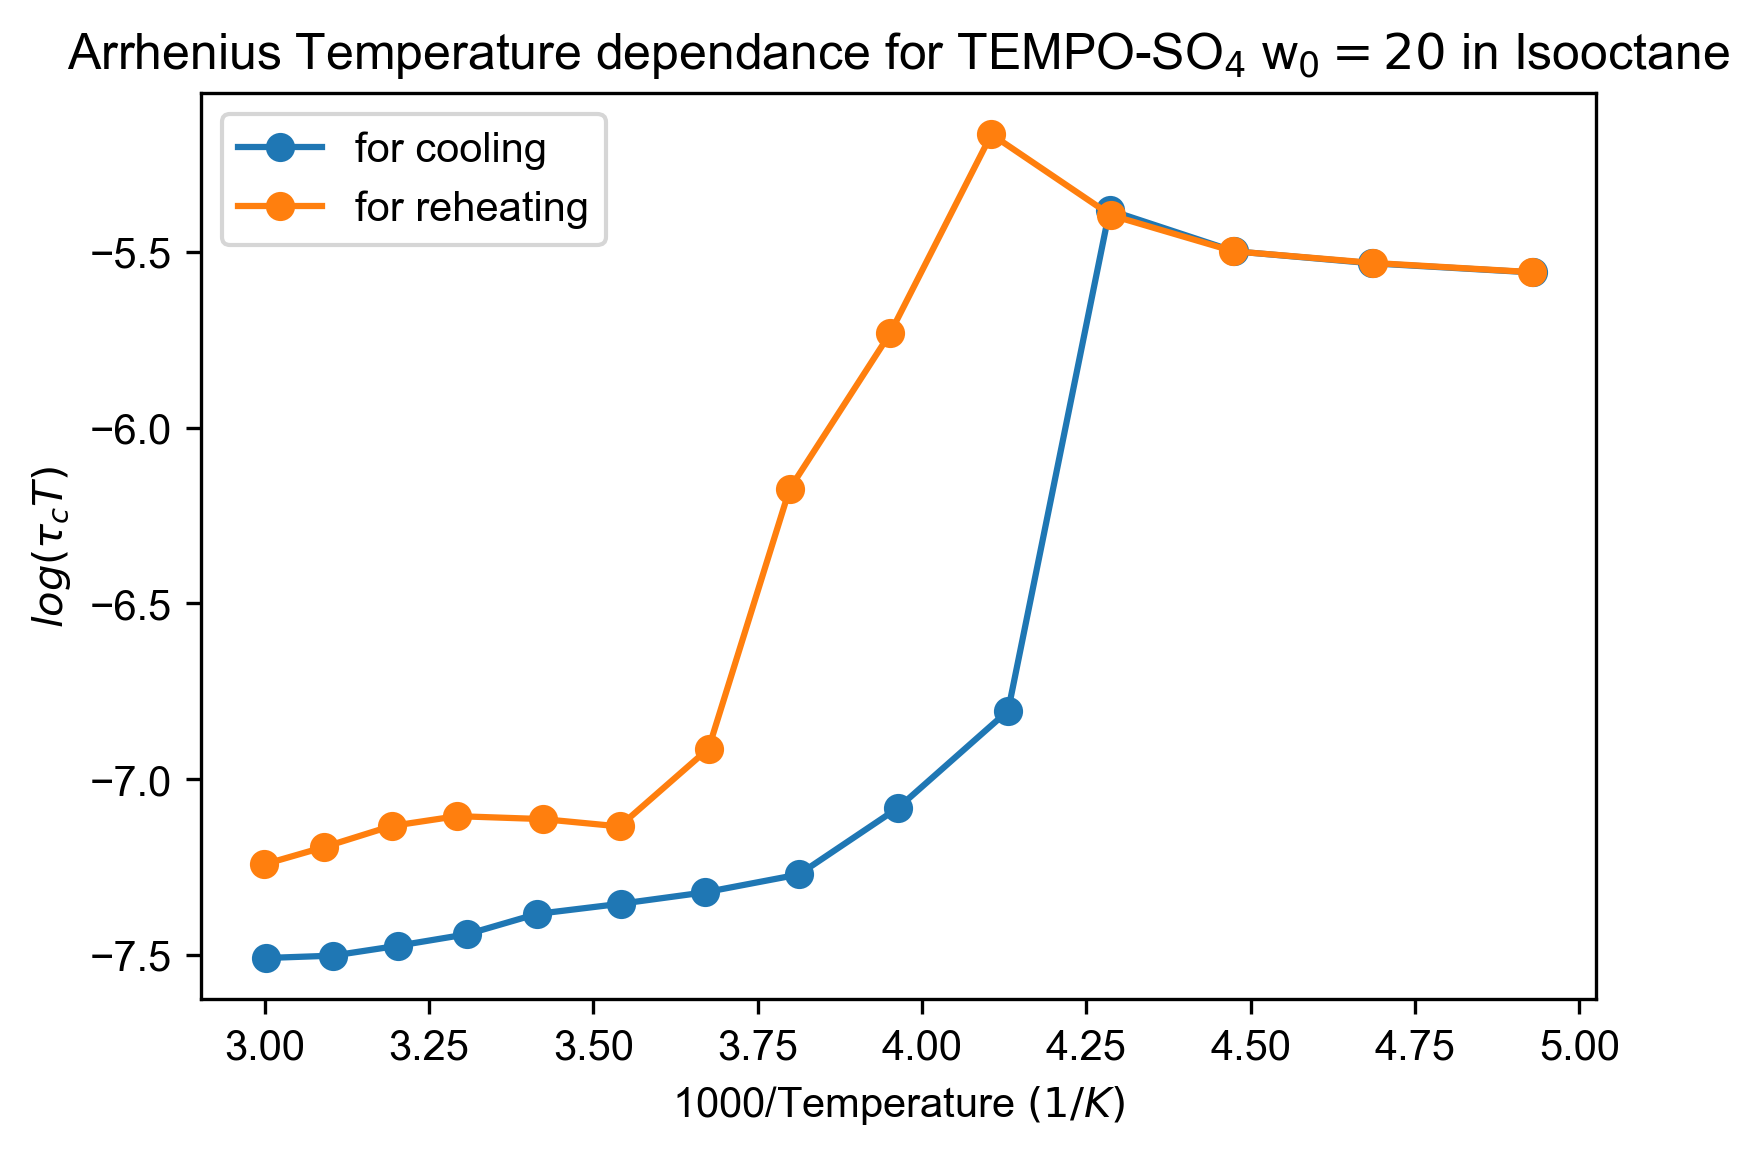

In [48]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(2.9,4.1)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in Isooctane')
show()

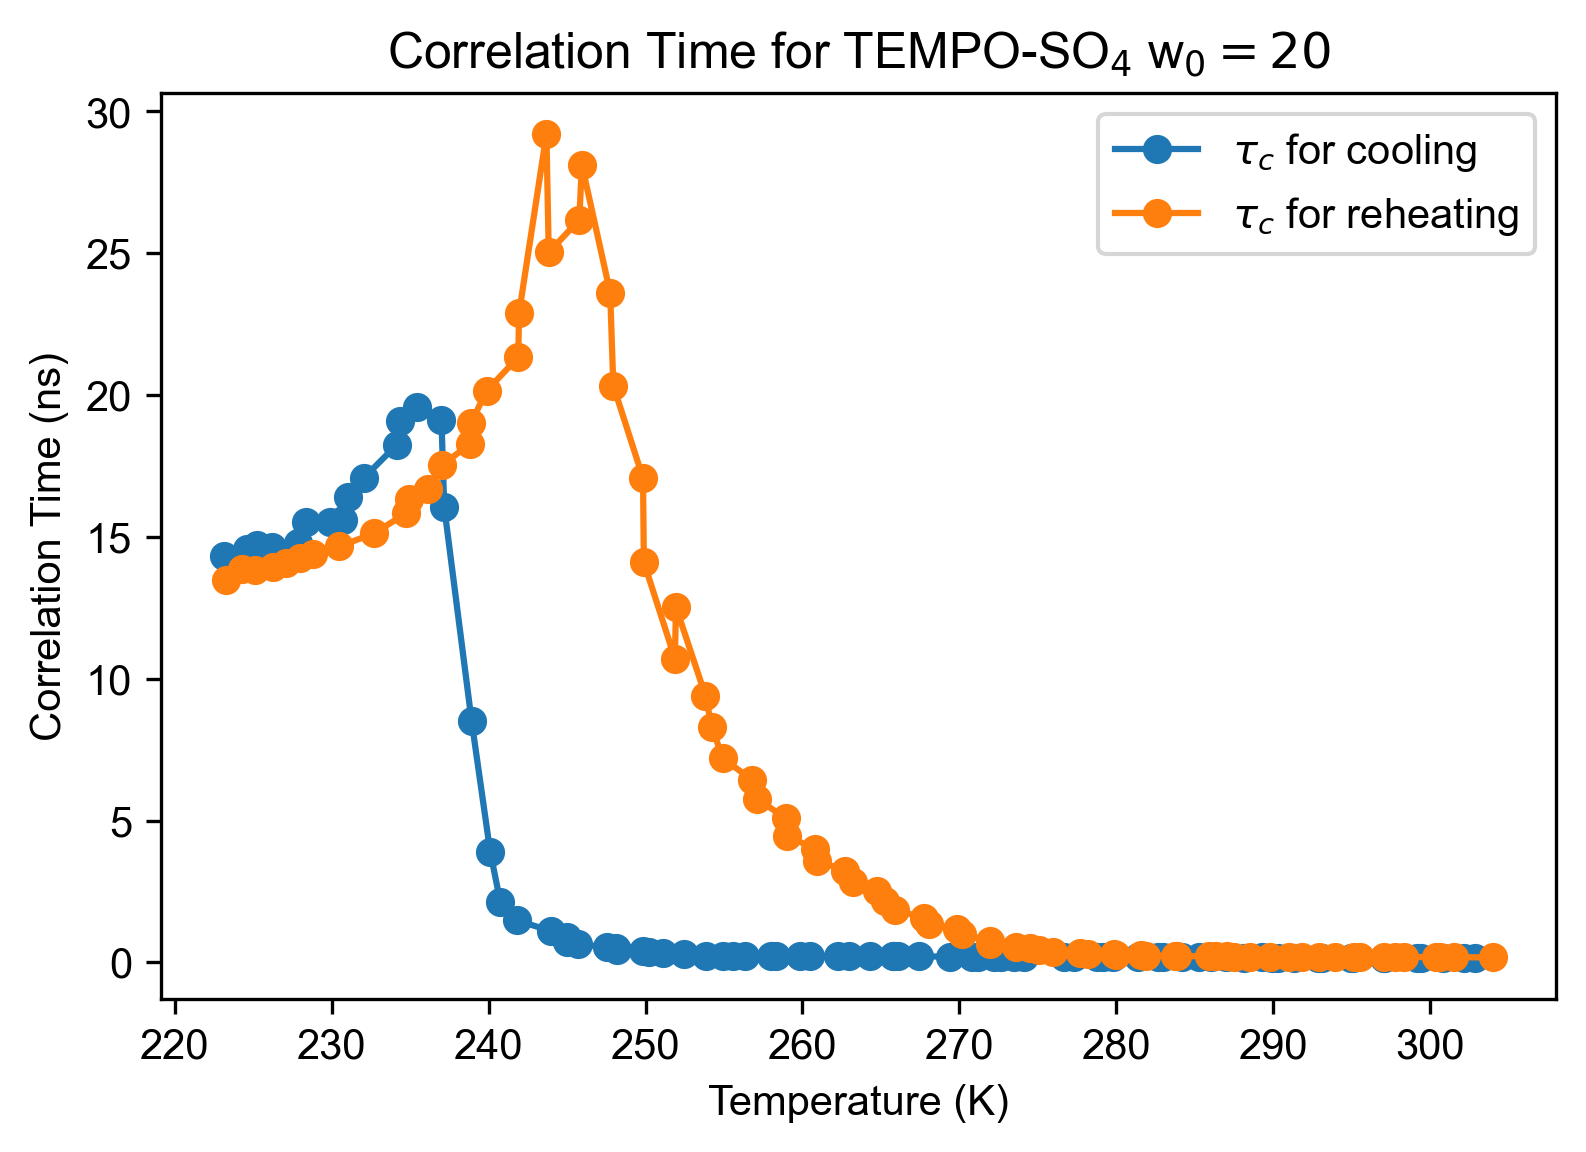

In [170]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling[4:], tau_cooling[4:]/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating[4:], tau_reheating[4:]/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
show()

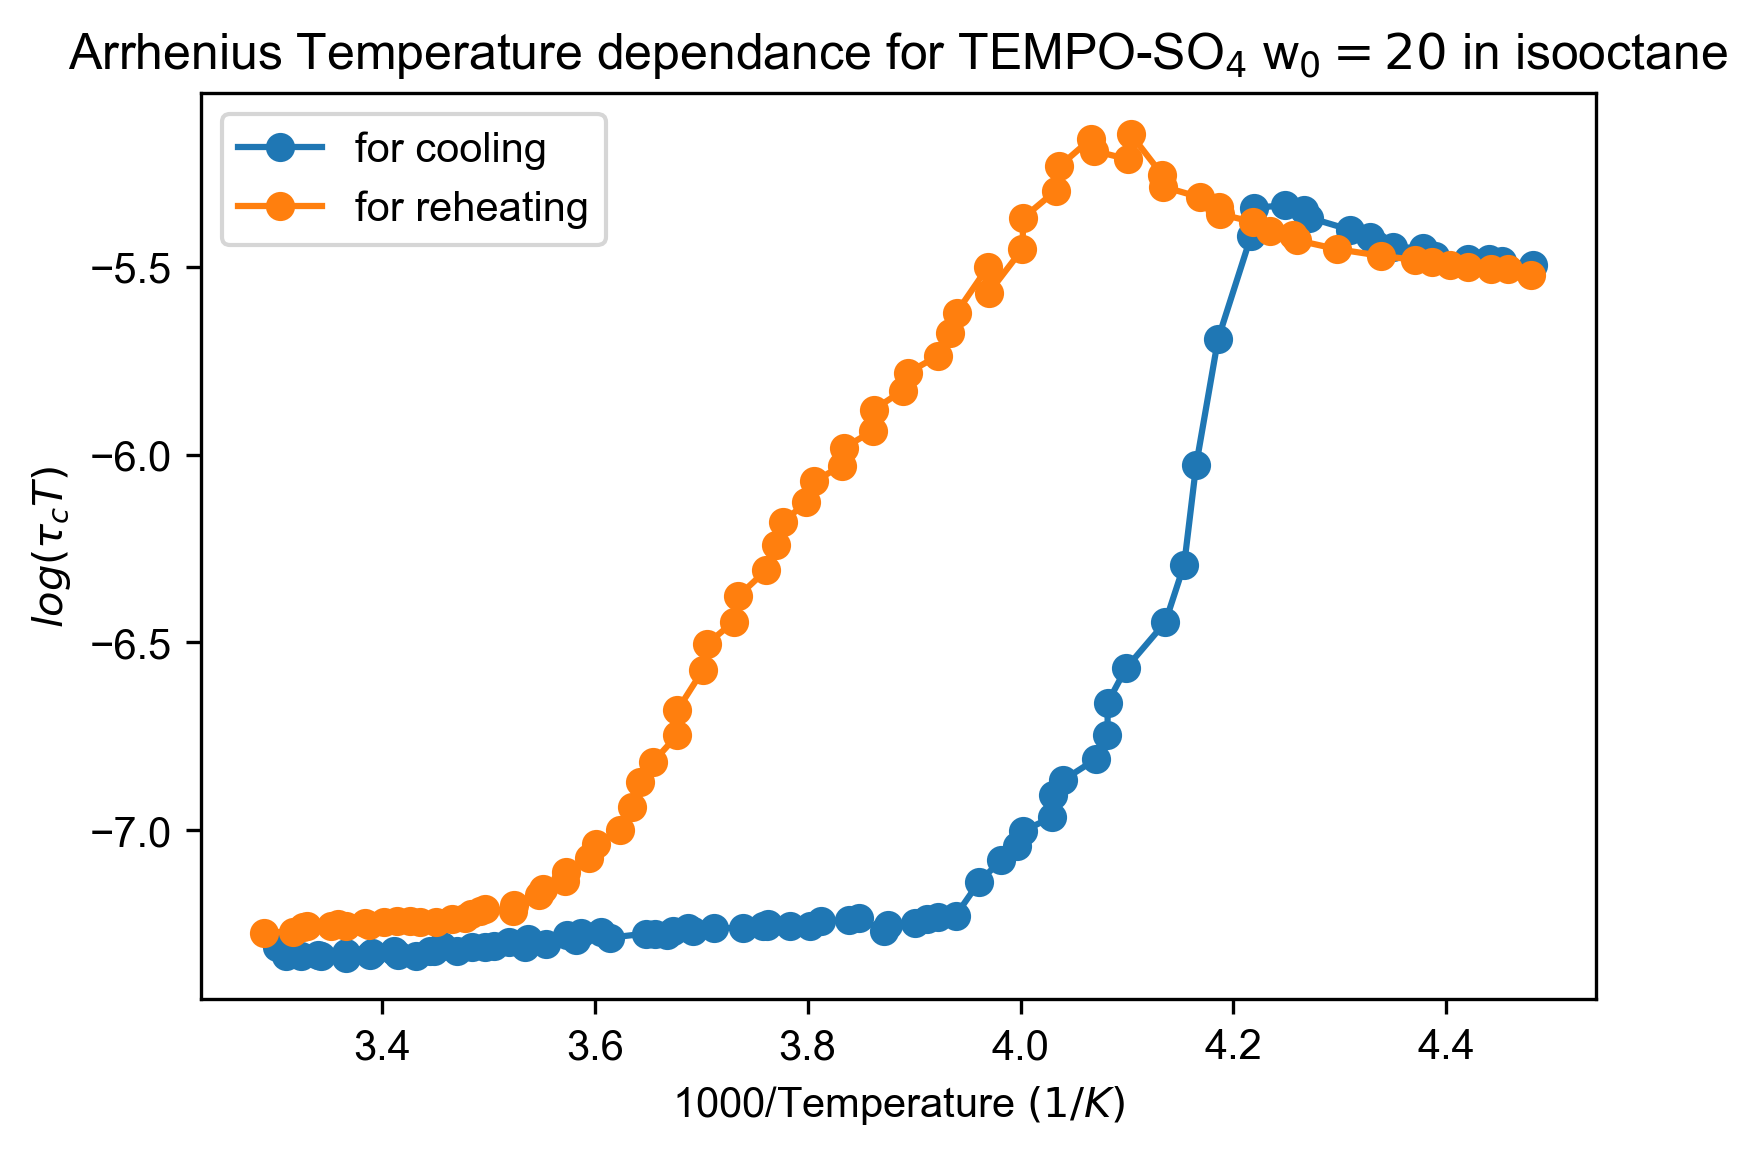

In [171]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling[4:], log10(tau_cooling[4:]*temp_cooling[4:]), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating[4:], log10(tau_reheating[4:]*temp_reheating[4:]), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(3,4)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane')
show()